# Formula 1 Podium Prediction — Milestone 1

**Task:** for every driver in every race, predict whether they finish on the podium (`positionOrder <= 3`)
using only information known **after qualifying and before the race starts**.

**Team:** _add names + IDs_

| # | Section | Owner |
|---|---|---|
| 0 | Setup & shared config | |
| 1 | Load raw data | |
| 2 | EDA before cleaning | |
| 3 | Cleaning: sentinels & semantic typing | |
| 4 | Key audit: primary & foreign keys | |
| 5 | Grain: one row per (raceId, driverId) | |
| 6 | EDA after cleaning | |
| 7 | Data-engineering questions Q1–Q3 | |
| 8 | Feature engineering & selection | |
| 9 | Train / validation / test split | |
| 10 | Models (baseline, statistical, shallow NN) | |
| 11 | Experiments: ablation & preprocessing order | |
| 12 | Explainability (SHAP, permutation, LIME) | |
| 13 | Inference function | |
| 14 | Limitations | |

**Golden rule:** a column may only become a feature if it is known before lights out.
Results, points, laps, status, pit stops, lap times and *post-race* standings are leakage.

## 0. Setup & shared config
Everyone uses these constants. Do not redefine them in later sections.

In [1]:
import sys, subprocess, importlib
for pkg in ["lime", "shap"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", pkg], check=False, capture_output=True)

import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)

TRAIN_END = 2019            # train: season <= 2019
VAL_YEARS = (2020, 2021)    # validation: 2020-2021
TEST_START = 2022           # test: season >= 2022
SENTINEL = r"\N"           # the dataset's placeholder for "missing"

## 1. Load raw data
Raw tables are loaded **as-is** into `raw` and never modified. All cleaning happens on copies in `clean`.

In [2]:
def find_data_dir():
    hits = glob.glob("/kaggle/input/**/circuits.csv", recursive=True) + glob.glob("./data/**/circuits.csv", recursive=True)
    if not hits:
        raise FileNotFoundError("circuits.csv not found - attach the F1 dataset via 'Add Input'")
    return os.path.dirname(hits[0])

DATA_DIR = find_data_dir()
TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
          "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops",
          "sprint_results", "seasons", "status"]

raw = {t: pd.read_csv(os.path.join(DATA_DIR, f"{t}.csv"), keep_default_na=False, dtype=str) for t in TABLES}

pd.DataFrame({t: {"rows": len(df), "cols": df.shape[1]} for t, df in raw.items()}).T

,rows,cols
circuits,77,9
constructors,212,5
constructor_results,12625,5
constructor_standings,13391,7
drivers,861,9
driver_standings,34863,7
races,1125,18
results,26759,18
qualifying,10494,9
lap_times,589081,6


In [3]:
# Column names per table - confirm they match the schema we planned around
for t, df in raw.items():
    print(f"{t:24s} {list(df.columns)}")

circuits                 ['circuitId', 'circuitRef', 'name', 'location', 'country', 'lat', 'lng', 'alt', 'url']
constructors             ['constructorId', 'constructorRef', 'name', 'nationality', 'url']
constructor_results      ['constructorResultsId', 'raceId', 'constructorId', 'points', 'status']
constructor_standings    ['constructorStandingsId', 'raceId', 'constructorId', 'points', 'position', 'positionText', 'wins']
drivers                  ['driverId', 'driverRef', 'number', 'code', 'forename', 'surname', 'dob', 'nationality', 'url']
driver_standings         ['driverStandingsId', 'raceId', 'driverId', 'points', 'position', 'positionText', 'wins']
races                    ['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']
results                  ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'posi

## 2. EDA before cleaning
Goal: show *with code and plots* what is wrong with the raw data, so every cleaning step is justified.

In [4]:
# Sentinel audit: how many "\N" values does each column contain?
sentinel_counts = []
for t, df in raw.items():
    for col in df.columns:
        n = (df[col] == SENTINEL).sum()
        if n:
            sentinel_counts.append({"table": t, "column": col, "n_sentinel": n, "pct": 100 * n / len(df)})
sentinel_df = pd.DataFrame(sentinel_counts).sort_values("pct", ascending=False)
sentinel_df

,table,column,n_sentinel,pct
0,constructor_results,status,12608,99.865347
13,races,sprint_time,1110,98.666667
12,races,sprint_date,1107,98.400000
9,races,fp3_time,1072,95.288889
7,races,fp2_time,1057,93.955556
5,races,fp1_time,1057,93.955556
11,races,quali_time,1057,93.955556
8,races,fp3_date,1053,93.600000
1,drivers,number,802,93.147503
4,races,fp1_date,1035,92.000000


### Observations: sentinel audit

**What we see:** many columns contain the placeholder `\N`, some almost entirely.

**Why, grouped by cause:**

| Group | Columns (pct missing) | Reason | Action |
|---|---|---|---|
| Never filled | `constructor_results.status` (99.9%) | Column is practically unused in the source | Document and drop |
| Didn't exist in older years | `races` session dates/times (92–99%), `races.time` (65%), `drivers.number` (93%), `drivers.code` (88%), `results.fastestLap*` / `rank` (68–69%) | Recorded only in recent seasons (sprints since 2021, permanent numbers since 2014, fastest-lap data since the 2000s) | Keep as NaN; not used as features |
| Didn't apply to that driver | `results.time` / `milliseconds` (71%) | Race time exists only for drivers who finished on the lead lap | Keep as NaN; post-race, never a feature |
| Not classified | `results.position` (40.9%) | Drivers who retired early or were disqualified have no official position | Confirms the target must use `positionOrder` (always filled), not `position` |
| Qualifying knockout | `qualifying.q2` (44.1%), `qualifying.q3` (65.0%) | Only 15 drivers reach Q2 and 10 reach Q3; before 2006 there was a single session, so q2/q3 are empty for all those years | Missingness carries information → derive `reached_Q3` / use `quali_position` instead of raw times |
| Rare gaps | `qualifying.q1` (1.5%), `results.number` (0.02%), `sprint_results` (2–6%) | A few drivers set no qualifying time (crash, mechanical issue); a handful of early results have no car number; sprint DNFs | Small; investigate the q1 rows, otherwise keep as NaN |

**Conclusion:** missing values are mostly *structural* (they have a real-world reason), not data errors.
Columns we will use as features (grid, qualifying position) need a separate coverage check per season, which is the next plot.

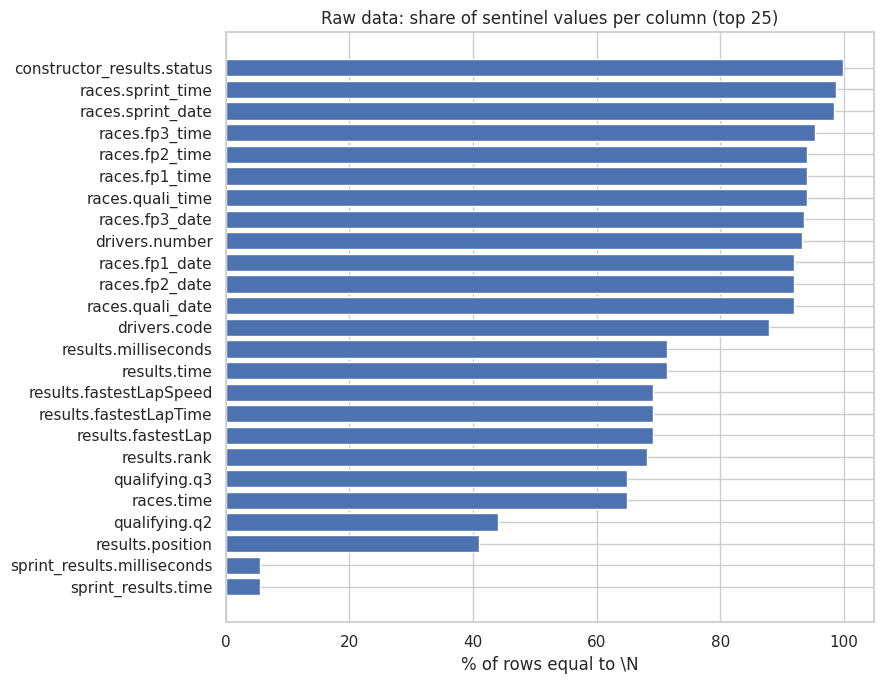

In [5]:
top = sentinel_df.head(25)
plt.figure(figsize=(9, 7))
plt.barh(top["table"] + "." + top["column"], top["pct"])
plt.gca().invert_yaxis()
plt.xlabel("% of rows equal to \\N")
plt.title("Raw data: share of sentinel values per column (top 25)")
plt.tight_layout(); plt.show()

In [6]:
auto = pd.read_csv(os.path.join(DATA_DIR, "results.csv"))
has_sentinel = (raw["results"] == SENTINEL).any()

typing_check = pd.DataFrame({
    "auto_dtype": auto.dtypes.astype(str),
    "contains_\\N": has_sentinel,
})
typing_check.sort_values("contains_\\N", ascending=False)

,auto_dtype,contains_\N
fastestLapSpeed,object,True
fastestLapTime,object,True
number,object,True
rank,object,True
position,object,True
fastestLap,object,True
milliseconds,object,True
time,object,True
resultId,int64,False
laps,int64,False


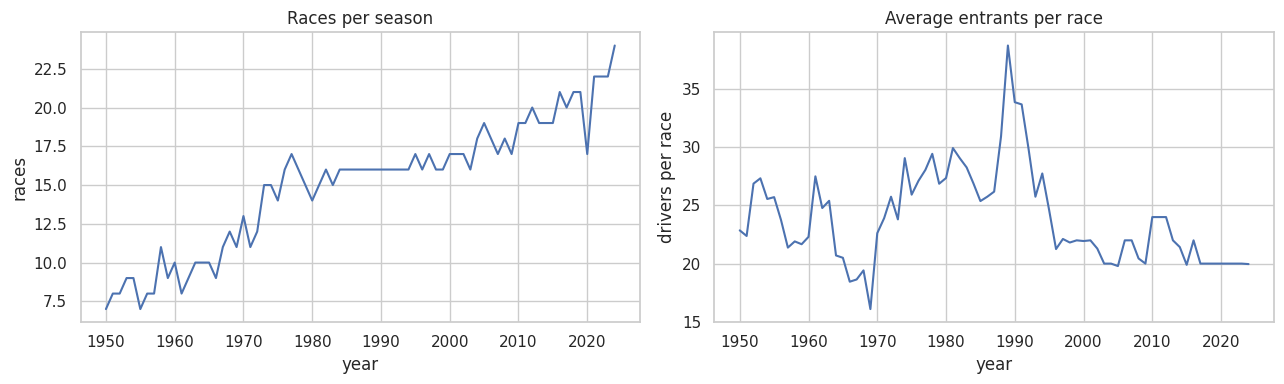

In [7]:
# How many races per season, and how many drivers enter each race?
res_y = (raw["results"][["raceId", "driverId", "positionOrder"]].astype(int)
         .merge(raw["races"][["raceId", "year"]].astype(int), on="raceId"))

per_season = res_y.groupby("year").agg(races=("raceId", "nunique"), entries=("driverId", "size"))
per_season["entrants_per_race"] = per_season["entries"] / per_season["races"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
per_season["races"].plot(ax=ax[0], title="Races per season")
per_season["entrants_per_race"].plot(ax=ax[1], title="Average entrants per race")
ax[0].set_ylabel("races"); ax[1].set_ylabel("drivers per race")
plt.tight_layout(); plt.show()

**Observation:** races per season grew from ~7 (1950) to ~24 (2024), so modern seasons contribute most rows.
Average entrants per race peaked at ~39 around 1989 (many non-qualifiers recorded in `results`) and has been ~20 since the late 1990s.
→ Field size varies a lot by era, which changes the podium base rate (next plot). Rows for drivers who never started (DNQ/DNPQ) need a keep/drop decision.

Overall podium rate: 12.7%


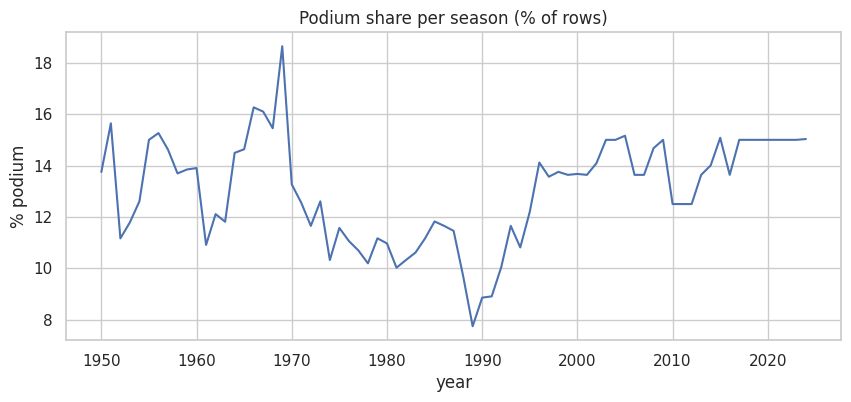

In [8]:
# What fraction of driver-race rows are podiums each season?
res_y["podium"] = (res_y["positionOrder"] <= 3).astype(int)
podium_rate = res_y.groupby("year")["podium"].mean() * 100

print(f"Overall podium rate: {res_y['podium'].mean():.1%}")
podium_rate.plot(figsize=(10, 4), title="Podium share per season (% of rows)")
plt.ylabel("% podium"); plt.show()

**Observation:** the overall podium rate is 12.7%, so the target is imbalanced (≈1 positive per 7 rows).
It drops to ~8% around 1989, when fields were largest, and is stable at ~15% (3 out of 20) in the modern era.


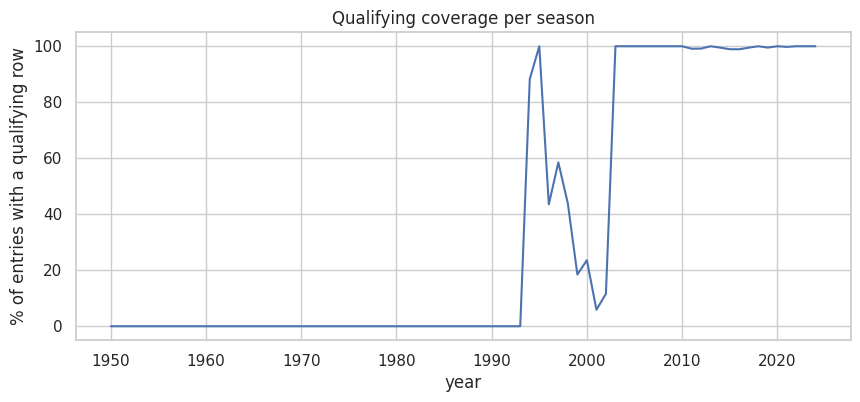

In [9]:
# For each season, what % of race entries have a qualifying record?
q_keys = raw["qualifying"][["raceId", "driverId"]].astype(int).drop_duplicates()
cov = res_y.merge(q_keys, on=["raceId", "driverId"], how="left", indicator=True)
cov["has_quali"] = cov["_merge"] == "both"
coverage = cov.groupby("year")["has_quali"].mean() * 100

coverage.plot(figsize=(10, 4), title="Qualifying coverage per season")
plt.ylabel("% of entries with a qualifying row"); plt.show()

**Observation:** qualifying records are absent before 1994, partial between 1996 and 2002 (5–60% of entries),
and complete from 2003 onwards. This is a gap in the dataset, not a rule change.
`grid` (from `results`) is available for all seasons.
→ Qualifying-based features are only reliable from 2003. Decision: **train from 2003**, the first season after which qualifying coverage is complete in every season, so qualifying features are real values rather than fills. Tested in 10.9 against training on all years (validation PR-AUC 0.732 vs 0.723).

In [10]:
# Validity check: are values in a possible range?
r = raw["results"].apply(pd.to_numeric, errors="coerce")
d = raw["drivers"].copy()
races_dt = raw["races"][["raceId", "date"]].assign(
    raceId=lambda x: x["raceId"].astype(int), date=lambda x: pd.to_datetime(x["date"]))

checks = {
    "grid < 0":                   (r["grid"] < 0).sum(),
    "grid == 0 (pit-lane / no start)": (r["grid"] == 0).sum(),
    "positionOrder < 1":          (r["positionOrder"] < 1).sum(),
    "points < 0":                 (r["points"] < 0).sum(),
    "laps < 0":                   (r["laps"] < 0).sum(),
}

# Driver age at each race: anyone younger than 16 or older than 60?
age = (r[["raceId", "driverId"]].astype(int)
       .merge(races_dt, on="raceId")
       .merge(d[["driverId", "dob"]].assign(driverId=lambda x: x["driverId"].astype(int),
                                            dob=lambda x: pd.to_datetime(x["dob"], errors="coerce")), on="driverId"))
age["age"] = (age["date"] - age["dob"]).dt.days / 365.25
checks["driver age < 16"] = (age["age"] < 16).sum()
checks["driver age > 60"] = (age["age"] > 60).sum()

pd.Series(checks, name="rows").to_frame()

,rows
grid < 0,0
grid == 0 (pit-lane / no start),1638
positionOrder < 1,0
points < 0,0
laps < 0,0
driver age < 16,0
driver age > 60,0


## Summary of data problems found in EDA

Each problem below was identified from the outputs above. The last column shows where (or how) it is handled.

### A. Format problems (fixed in Section 3)

| # | Problem | Explanation | Evidence | Planned fix |
|---|---|---|---|---|
| 1 | `\N` used as a missing-value placeholder | The dataset writes "missing" as the text `\N`, which pandas does not recognise as empty | Sentinel audit: 30 columns affected | Replace `\N` with `NaN` |
| 2 | Numbers and dates stored as text | One `\N` in a column forces the whole column to be read as text, so no math or comparisons are possible (e.g. `"10" < "3"` as text) | Typing check: every column containing `\N` loads as `object` | Convert each column to its real type (int, float, datetime) |
| 3 | Lap and pit-stop times stored as text (`"1:27.264"`) | Times cannot be subtracted or averaged, so features like *gap to pole* cannot be computed | `qualifying.q1/q2/q3`, `pit_stops.duration`, `results.fastestLapTime` | Convert to numeric seconds (`87.264`) |
| 4 | Columns with almost no data | Some columns are nearly empty and add nothing | `constructor_results.status` 99.9% missing | Document and drop |

### B. Structural problems (checked in Sections 4–5)

| # | Problem | Explanation | Planned check |
|---|---|---|---|
| 5 | Possible duplicate (raceId, driverId) rows | In the 1950s two drivers could share one car, so a driver may appear twice in a race. The modeling table needs exactly one row per driver per race | Count duplicates, then apply a documented deduplication rule |
| 6 | Possible broken links between tables | An ID in one table (e.g. `results.driverId`) might not exist in the table it points to | Primary-key and foreign-key audit |

### C. Missing values with a real-world meaning (handled in cleaning / feature engineering)

| # | Problem | Explanation | Evidence | Planned handling |
|---|---|---|---|---|
| 7 | `q2` / `q3` empty for many drivers | Qualifying is a knockout: only 15 drivers reach Q2 and 10 reach Q3, so emptiness means "eliminated earlier", not an error | q2 44%, q3 65% missing | Do not fill with 0 (that would mean a 0-second lap). Use `quali_pos` and `gap_to_pole_pct` instead of raw times; a missing lap time gets the `no_quali_time` flag (Section 8) |
| 8 | `position` empty for unclassified drivers | Drivers who complete less than 90% of the race distance get no official position | `results.position` 41% missing | Target uses `positionOrder` (always filled) instead of `position` |
| 9 | Qualifying data missing for whole eras | The dataset has no qualifying records before 1994 and only partial records in 1996–2002 (a recording gap, not a rule change) | Qualifying-coverage plot | **Team decision:** train from 2003 / keep all years with a `has_quali` flag / fall back to `grid` |

### D. Misleading or era-dependent values (team decisions)

| # | Problem | Explanation | Evidence | Planned handling |
|---|---|---|---|---|
| 10 | `grid = 0` | Means a pit-lane start (car changed after qualifying) or a driver who never started. As a number, 0 looks *better* than pole position (1), the opposite of reality | Validity check | Recode (e.g. to the back of the grid) and/or add a `pit_lane_start` flag |
| 11 | Drivers who never started (DNQ / DNPQ) | In the 1980s–90s up to 39 cars entered but only 26 could start. Non-starters cannot reach the podium | Entrants peak of ~39 around 1989 | **Team decision:** drop non-starters from the modeling table or keep them as guaranteed negatives |
| 12 | Indy 500 races (1950–1960) | Counted for the championship but almost no regular F1 drivers entered, so it behaves like a different series | F1 brief | Exclude and document |
| 13 | Field size varies by era (~20 to ~39) | The same grid position means different things: 15th of 20 is near the back, 15th of 39 is mid-field | Entrants-per-race plot | Consider a relative-grid feature (`grid / field_size`) |
| 14 | Imbalanced target that changes by era | Only 12.7% of rows are podiums, so a model that always says "no" is 87% accurate but useless. The rate ranges from ~8% (large fields) to ~15% (modern era) | Podium-share plot | Use PR-AUC as the primary metric; consider class weighting and the training-year decision |

### E. Risks for later sections

| # | Problem | Explanation | Where handled |
|---|---|---|---|
| 15 | Team renames reset history | The same team under a new name (Toleman → Benetton → Renault → Lotus → Alpine) gets a new `constructorId` | Section 8: team-lineage mapping + reset of re-used IDs |
| 16 | Leakage columns next to valid ones | `results` mixes pre-race info (`grid`) with post-race info (`points`, `laps`, `statusId`, `time`) | Feature section: only pre-race columns allowed |

## 3. Cleaning: sentinels & semantic typing
Steps, applied to copies:
1. Replace `\N` with `NaN`.
2. Convert ID / numeric columns to numbers.
3. Convert date strings to `datetime`.
4. Convert lap-time / duration strings (`"1:27.264"`, `"21.664"`) to numeric **seconds**.

In [11]:
def to_seconds(s):
    """'1:27.264' -> 87.264 ; '21.664' -> 21.664 ; '1:02:03.5' -> 3723.5 ; NaN/garbage -> NaN"""
    if pd.isna(s):
        return np.nan
    s = str(s).strip().lstrip("+")
    try:
        parts = [float(p) for p in s.split(":")]
    except ValueError:
        return np.nan
    secs = 0.0
    for p in parts:
        secs = secs * 60 + p
    return secs

assert to_seconds("1:27.264") == 87.264
assert to_seconds("21.664") == 21.664
assert np.isnan(to_seconds(np.nan))

In [12]:
DATE_COLS = {"races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
             "drivers": ["dob"]}
TIME_COLS = {"qualifying": ["q1", "q2", "q3"],
             "lap_times": ["time"],
             "pit_stops": ["duration"],
             "results": ["fastestLapTime"],
             "sprint_results": ["fastestLapTime"]}
# Text columns that must stay strings
TEXT_COLS = {"circuitRef", "name", "location", "country", "url", "constructorRef", "nationality",
             "driverRef", "code", "forename", "surname", "positionText", "status", "time"}

clean = {}
for t, df in raw.items():
    d = df.copy().replace([SENTINEL, ""], np.nan)   # treat both "\N" and blank cells as missing
    for col in d.columns:
        if col in DATE_COLS.get(t, []):
            d[col] = pd.to_datetime(d[col], errors="coerce")
        elif col in TIME_COLS.get(t, []):
            d[col + "_s"] = d[col].map(to_seconds)      # keep original text, add numeric seconds
        elif col not in TEXT_COLS and not col.endswith("_time"):
            converted = pd.to_numeric(d[col], errors="coerce")
            # only convert if it doesn't destroy real values
            if converted.notna().sum() == d[col].notna().sum():
                d[col] = converted
    clean[t] = d

# Sanity: raw must be untouched
assert (raw["results"] == SENTINEL).any().any(), "raw was modified!"
clean["results"].dtypes

resultId              int64
raceId                int64
driverId              int64
constructorId         int64
number              float64
grid                  int64
position            float64
positionText         object
positionOrder         int64
points              float64
laps                  int64
time                 object
milliseconds        float64
fastestLap          float64
rank                float64
fastestLapTime       object
fastestLapSpeed     float64
statusId              int64
fastestLapTime_s    float64
dtype: object

In [13]:
# Check conversions did not silently lose values (non-null before vs after)
loss = []
for t in TIME_COLS:
    for col in TIME_COLS[t]:
        if col in clean[t]:
            before, after = clean[t][col].notna().sum(), clean[t][col + "_s"].notna().sum()
            loss.append({"table": t, "column": col, "non_null_text": before, "non_null_seconds": after, "lost": before - after})
pd.DataFrame(loss)

,table,column,non_null_text,non_null_seconds,lost
0,qualifying,q1,10338,10338,0
1,qualifying,q2,5847,5847,0
2,qualifying,q3,3629,3629,0
3,lap_times,time,589081,589081,0
4,pit_stops,duration,11371,11371,0
5,results,fastestLapTime,8252,8252,0
6,sprint_results,fastestLapTime,351,351,0


In [14]:
# constructor_results.status is 99.9% empty (see sentinel audit) → drop it
clean["constructor_results"] = clean["constructor_results"].drop(columns="status", errors="ignore")

In [15]:
# 1) No "\N" left anywhere
remaining = {t: int((df.astype(str) == SENTINEL).sum().sum()) for t, df in clean.items()}
print("Remaining \\N per table:", remaining)

# 2) Types before vs after for the main table
pd.DataFrame({"raw_dtype": raw["results"].dtypes.astype(str),
              "clean_dtype": clean["results"].dtypes.astype(str)})

Remaining \N per table: {'circuits': 0, 'constructors': 0, 'constructor_results': 0, 'constructor_standings': 0, 'drivers': 0, 'driver_standings': 0, 'races': 0, 'results': 0, 'qualifying': 0, 'lap_times': 0, 'pit_stops': 0, 'sprint_results': 0, 'seasons': 0, 'status': 0}


,raw_dtype,clean_dtype
constructorId,object,int64
driverId,object,int64
fastestLap,object,float64
fastestLapSpeed,object,float64
fastestLapTime,object,object
fastestLapTime_s,NaN,float64
grid,object,int64
laps,object,int64
milliseconds,object,float64
number,object,float64


**Cleaning summary (problems 1–4):**
- Replaced the `\N` placeholder with `NaN` in all tables (verified: 0 remaining).
- Converted ID, count and numeric columns to numbers, and date columns to `datetime`.
  A column is only converted when no value is lost; genuine text columns (names, `positionText`, race-gap `time`) stay as text.
- Converted lap and pit-stop times to seconds in new `_s` columns, keeping the original text for traceability (loss check: 0 values lost).
- Dropped `constructor_results.status` (99.9% missing).
- Raw tables are untouched (assert check passed).

Problems 9–12 (training years, `grid = 0`, non-starters, Indy 500) are left for a team decision.

## 4. Key audit: primary & foreign keys

In [16]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "seasons": ["year"], "status": ["statusId"],
    "results": ["resultId"], "qualifying": ["qualifyId"], "sprint_results": ["resultId"],
    "driver_standings": ["driverStandingsId"], "constructor_standings": ["constructorStandingsId"],
    "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
pk_report = []
for t, keys in PRIMARY_KEYS.items():
    d = clean[t]
    pk_report.append({"table": t, "key": "+".join(keys),
                      "null_rows": int(d[keys].isna().any(axis=1).sum()),
                      "duplicate_rows": int(d.duplicated(keys).sum())})
pd.DataFrame(pk_report)

,table,key,null_rows,duplicate_rows
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,drivers,driverId,0,0
3,races,raceId,0,0
4,seasons,year,0,0
5,status,statusId,0,0
6,results,resultId,0,0
7,qualifying,qualifyId,0,0
8,sprint_results,resultId,0,0
9,driver_standings,driverStandingsId,0,0


In [17]:
# (child table, child column, parent table, parent column)
FOREIGN_KEYS = [("races", "year", "seasons", "year"), ("races", "circuitId", "circuits", "circuitId")]
for child in ["results", "qualifying", "sprint_results", "driver_standings", "lap_times", "pit_stops"]:
    FOREIGN_KEYS += [(child, "raceId", "races", "raceId"), (child, "driverId", "drivers", "driverId")]
for child in ["results", "qualifying", "sprint_results", "constructor_standings", "constructor_results"]:
    FOREIGN_KEYS += [(child, "constructorId", "constructors", "constructorId")]
FOREIGN_KEYS += [("constructor_standings", "raceId", "races", "raceId"),
                 ("constructor_results", "raceId", "races", "raceId"),
                 ("results", "statusId", "status", "statusId"),
                 ("sprint_results", "statusId", "status", "statusId")]

fk_report = []
for ct, cc, pt, pc in FOREIGN_KEYS:
    vals = clean[ct][cc].dropna()
    orphans = ~vals.isin(clean[pt][pc])
    fk_report.append({"child": f"{ct}.{cc}", "parent": f"{pt}.{pc}",
                      "null_fk": int(clean[ct][cc].isna().sum()), "orphans": int(orphans.sum())})
fk_df = pd.DataFrame(fk_report)
fk_df

,child,parent,null_fk,orphans
0,races.year,seasons.year,0,0
1,races.circuitId,circuits.circuitId,0,0
2,results.raceId,races.raceId,0,0
3,results.driverId,drivers.driverId,0,0
4,qualifying.raceId,races.raceId,0,0
5,qualifying.driverId,drivers.driverId,0,0
6,sprint_results.raceId,races.raceId,0,0
7,sprint_results.driverId,drivers.driverId,0,0
8,driver_standings.raceId,races.raceId,0,0
9,driver_standings.driverId,drivers.driverId,0,0


**Key audit result:** every table's primary key is unique and non-null, and every foreign key
(results/qualifying/sprint/standings/lap times/pit stops → races, drivers, constructors, status; races → circuits, seasons)
points to an existing row (0 duplicates, 0 nulls, 0 orphans).
→ Joins between tables will not drop or mismatch rows, so no key-related cleaning is needed.

## 5. Grain: one row per (raceId, driverId)
The modeling table needs exactly one row per driver per race. Shared drives (mainly the 1950s) break this.

176 rows involved in 85 duplicated (raceId, driverId) pairs


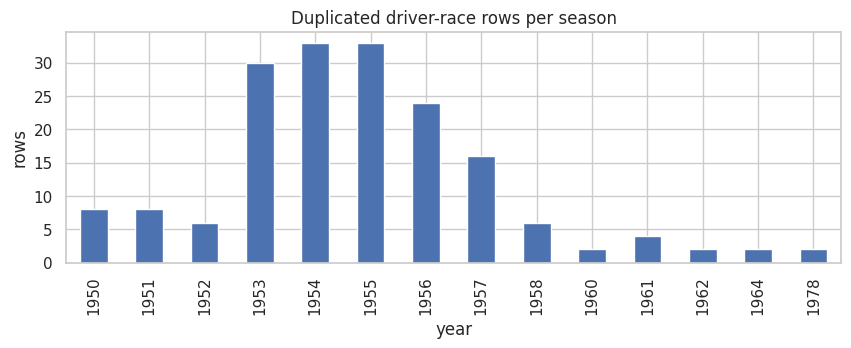

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,fastestLapTime_s,year,name
0,13189,540,229,54,10.0,0,NaN,F,26,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81,NaN,1978,Italian Grand Prix
1,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97,NaN,1978,Italian Grand Prix
2,17363,717,373,172,1.0,1,7.0,7,7,0.0,102,NaN,NaN,NaN,NaN,NaN,NaN,60,NaN,1964,United States Grand Prix
175,24304,717,373,172,2.0,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98,NaN,1964,United States Grand Prix
3,17741,733,465,172,48.0,0,NaN,W,22,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54,NaN,1962,British Grand Prix
4,17744,733,465,97,50.0,0,NaN,W,25,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54,NaN,1962,British Grand Prix
5,17962,742,475,102,26.0,20,NaN,D,19,0.0,56,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,1961,British Grand Prix
6,17964,742,475,172,28.0,5,NaN,R,21,0.0,44,NaN,NaN,NaN,NaN,NaN,NaN,23,NaN,1961,British Grand Prix
7,18063,745,418,172,22.0,11,NaN,R,17,0.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6,NaN,1961,United States Grand Prix
174,24303,745,418,172,21.0,15,11.0,11,11,0.0,92,NaN,NaN,NaN,NaN,NaN,NaN,18,NaN,1961,United States Grand Prix


In [18]:
res = clean["results"]
dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = res[dup_mask].merge(clean["races"][["raceId", "year", "name"]], on="raceId")
print(f"{dup_mask.sum()} rows involved in {res[dup_mask].groupby(['raceId','driverId']).ngroups} duplicated (raceId, driverId) pairs")
dups.groupby("year").size().plot(kind="bar", figsize=(10, 3), title="Duplicated driver-race rows per season")
plt.ylabel("rows"); plt.show()
dups.sort_values(["raceId", "driverId"]).head(10)

In [19]:
# RULE (justified in the markdown below):
# keep the car the driver STARTED in (grid > 0); if still tied, keep the best positionOrder.
def dedupe_results(df):
    d = df.copy()
    d["_started"] = (d["grid"].fillna(0) > 0).astype(int)
    d = d.sort_values(["raceId", "driverId", "_started", "positionOrder"], ascending=[True, True, False, True])
    return d.drop_duplicates(["raceId", "driverId"], keep="first").drop(columns="_started")

results_dedup = dedupe_results(res)
assert not results_dedup.duplicated(["raceId", "driverId"]).any()
print(f"rows before: {len(res)}, after: {len(results_dedup)}, removed: {len(res) - len(results_dedup)}")

rows before: 26759, after: 26668, removed: 91


**Grain fix (problem 5):** 85 (raceId, driverId) pairs appear more than once (176 rows), almost all in 1950–1957,
when drivers could take over a teammate's car mid-race (banned after 1957).
A driver with two rows in the same race would get two contradicting labels (e.g. one podium, one not) and be double-counted in statistics.

**Rule:** keep the row of the car the driver **started** in (`grid > 0`); if still tied, keep the best `positionOrder`.
**Justification:** the prediction is made before the race, when only the starting car is known; a mid-race car swap is post-race information.
**Result:** 91 rows removed (26,759 → 26,668); verified one row per (raceId, driverId).

In [20]:
dups[dups["year"] == 1978]

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,fastestLapTime_s,year,name
0,13189,540,229,54,10.0,0,NaN,F,26,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81,NaN,1978,Italian Grand Prix
1,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97,NaN,1978,Italian Grand Prix


In [21]:
# From here on, the deduplicated table IS the clean results table
clean["results"] = results_dedup

In [22]:
GRAIN = {
    "qualifying":            ["raceId", "driverId"],
    "sprint_results":        ["raceId", "driverId"],
    "driver_standings":      ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"],
    "constructor_results":   ["raceId", "constructorId"],
    "races":                 ["year", "round"],  
}
pd.DataFrame([{"table": t, "grain": " + ".join(k), "duplicate_rows": int(clean[t].duplicated(k).sum())}
              for t, k in GRAIN.items()])

,table,grain,duplicate_rows
0,qualifying,raceId + driverId,0
1,sprint_results,raceId + driverId,0
2,driver_standings,raceId + driverId,0
3,constructor_standings,raceId + constructorId,0
4,constructor_results,raceId + constructorId,0
5,races,year + round,0


## 6. EDA after cleaning
The table below compares every table before and after cleaning (rows, missing values). The cleaned data is then re-examined
through the data decisions below and the feature evidence in Section 8.

In [23]:
summary = pd.DataFrame({
    "rows_raw":      {t: len(raw[t]) for t in TABLES},
    "rows_clean":    {t: len(clean[t]) for t in TABLES},
    "missing_raw":   {t: int(((raw[t] == SENTINEL) | (raw[t] == "")).sum().sum()) for t in TABLES},
    # count only columns that exist in raw (ignore the added *_s seconds columns)
    "missing_clean": {t: int(clean[t][clean[t].columns.intersection(raw[t].columns)].isna().sum().sum()) for t in TABLES},
})
summary["rows_removed"] = summary["rows_raw"] - summary["rows_clean"]
summary

,rows_raw,rows_clean,missing_raw,missing_clean,rows_removed
circuits,77,77,0,0,0
constructors,212,212,0,0,0
constructor_results,12625,12625,12608,0,0
constructor_standings,13391,13391,0,0,0
drivers,861,861,1559,1559,0
driver_standings,34863,34863,0,0,0
races,1125,1125,11349,11349,0
results,26759,26668,122887,122260,91
qualifying,10494,10494,11668,11668,0
lap_times,589081,589081,0,0,0


**Before vs after cleaning:**
- Row counts are unchanged in every table except `results`, where 91 duplicate (raceId, driverId) rows were removed.
- Missing values are preserved: every `\N` or blank cell in the raw data is now a real `NaN` in the clean data,
  so nothing was lost or invented (the comparison counts only original columns; the added `*_s` seconds columns repeat their source's gaps).
- `constructor_results` drops to 0 missing because its 99.9%-empty `status` column was removed.
- `results` has slightly fewer missing values than raw because the removed duplicate rows took their gaps with them.

In [24]:
# ===== Data decisions (fixed for every modeling attempt) =====
EXCLUDE_INDY500   = True   # decision 4
DROP_NON_STARTERS = True   # decision 3
# decision 2 (grid = 0 → back of grid + flag) is always applied

base = clean["results"].merge(
    clean["races"][["raceId", "year", "round", "name", "date", "circuitId"]], on="raceId")

is_indy     = base["name"].str.contains("Indianapolis 500", case=False)
non_starter = (base["grid"] == 0) & (base["laps"] == 0)
pit_lane    = (base["grid"] == 0) & (base["laps"] > 0)

print(f"Rows before decisions:   {len(base)}")
print(f"  Indy 500 rows:         {is_indy.sum()}")
print(f"  Non-starter rows:      {(non_starter & ~is_indy).sum()}")
print(f"  Pit-lane-start rows:   {(pit_lane & ~is_indy).sum()}")

# Decisions 3 + 4: keep only real starters of real F1 races
keep = pd.Series(True, index=base.index)
if EXCLUDE_INDY500:   keep &= ~is_indy
if DROP_NON_STARTERS: keep &= ~non_starter
base = base[keep].copy()

# Decision 2: pit-lane starters → back of the grid, plus a flag
base["pit_lane_start"] = ((base["grid"] == 0) & (base["laps"] > 0)).astype(int)
back_of_grid = base.groupby("raceId")["grid"].transform("max") + 1
base["grid"] = np.where(base["pit_lane_start"] == 1, back_of_grid, base["grid"])

# Target: podium = finished in the top 3
base["podium"] = (base["positionOrder"] <= 3).astype(int)

assert (base["grid"] > 0).all(), "grid = 0 still present"
assert not base.duplicated(["raceId", "driverId"]).any(), "duplicate driver-race rows"
print(f"Rows after decisions:    {len(base)}")

Rows before decisions:   26668
  Indy 500 rows:         381
  Non-starter rows:      1563
  Pit-lane-start rows:   72
Rows after decisions:    24724


**Data decisions (applied to every modeling attempt):** 26,668 → 24,724 rows.
- **Indy 500 excluded** (381 rows): counted for the championship 1950–1960, but entered almost exclusively by American drivers who did not race other F1 events, so it behaves like a separate series.
- **Non-starters dropped** (1,563 rows, `grid = 0` and `laps = 0`): did-not-qualify / did-not-start entries cannot reach the podium, and at the prediction cutoff (grid set) it is already known they are not racing.
- **Pit-lane starters kept** (72 rows): recoded to the back of the grid (largest grid in the race + 1) and flagged with `pit_lane_start = 1`. `laps` is used only to identify these rows; a pit-lane start is announced before the race.
- **Target:** `podium = 1` if `positionOrder ≤ 3`.
- Verified: no `grid = 0` and no duplicate (raceId, driverId) rows remain.

**Training years (decision 1)** is the only setting that differs between attempts:
`from_2003` (complete qualifying data) vs `all_years`. Both are evaluated on the same 2020–2021 validation set in Section 10.

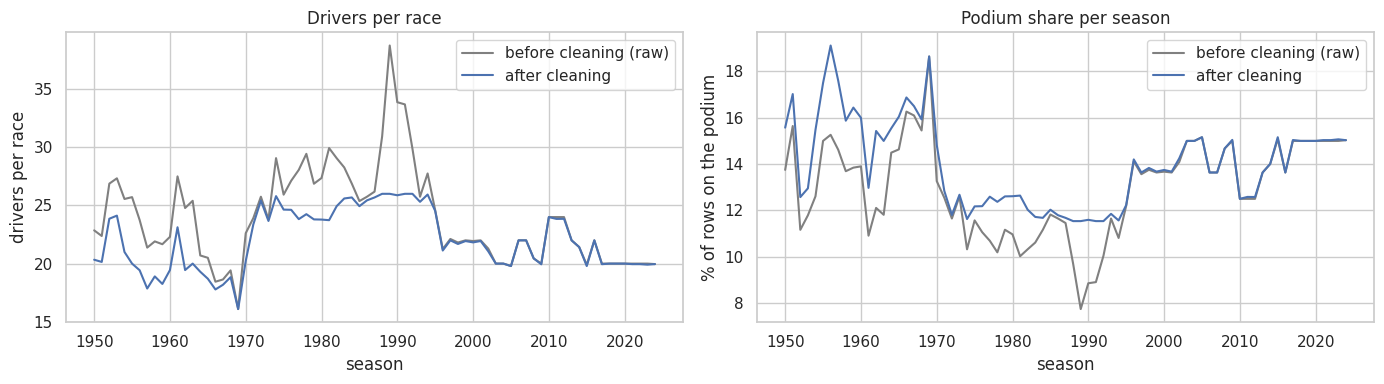

Overall podium rate: 12.7% before → 13.6% after cleaning


In [25]:
# ===== 6.2 Before vs after cleaning: the same EDA plots on raw and cleaned data =====
before = res_y.groupby("year").agg(rows=("driverId", "size"), races=("raceId", "nunique"), podium=("podium", "mean"))
after  = base.groupby("year").agg(rows=("driverId", "size"), races=("raceId", "nunique"), podium=("podium", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(before.index, before["rows"] / before["races"], label="before cleaning (raw)", color="grey")
axes[0].plot(after.index,  after["rows"] / after["races"],   label="after cleaning")
axes[0].set_title("Drivers per race"); axes[0].set_ylabel("drivers per race")
axes[1].plot(before.index, before["podium"] * 100, label="before cleaning (raw)", color="grey")
axes[1].plot(after.index,  after["podium"] * 100,  label="after cleaning")
axes[1].set_title("Podium share per season"); axes[1].set_ylabel("% of rows on the podium")
for ax in axes: ax.set_xlabel("season"); ax.legend()
plt.tight_layout(); plt.show()

print(f"Overall podium rate: {res_y['podium'].mean():.1%} before → {base['podium'].mean():.1%} after cleaning")

**Observation (after cleaning):** the same two EDA plots, before and after cleaning.
- **Drivers per race:** the 1989 peak of ~39 entrants per race drops to ~26, the maximum number of cars allowed to start in that era:
  the extra rows were non-qualifiers counted as entrants. The 1950s also drop (Indy 500 and duplicate shared-drive rows removed).
  From the late 1990s the two lines are identical, because modern data had almost nothing to remove.
- **Podium share:** the lowest season rises from ~8% (1989) to ~11.5%, and the overall rate from 12.7% to 13.6%.
- The cleaned data therefore describes only drivers who actually started, which is the population the model predicts for.

In [26]:
# ===== Decision 1: training years (the ONE thing that differs between attempts) =====
YEAR_OPTIONS = {"from_2003": 2003, "all_years": 1950}

model_bases = {name: base[base["year"] >= start].copy() for name, start in YEAR_OPTIONS.items()}

pd.DataFrame({
    name: {"first_year": d["year"].min(),
           "rows_total": len(d),
           "rows_train (≤2019)": int((d["year"] <= TRAIN_END).sum()),
           "podium_rate": f"{d['podium'].mean():.1%}"}
    for name, d in model_bases.items()
}).T

,first_year,rows_total,rows_train (≤2019),podium_rate
from_2003,2003,8956,6821,14.3%
all_years,1950,24724,22589,13.6%


**Training-year options:** `from_2003` has 6,821 training rows (2003–2019) and `all_years` has 22,589 (1950–2019),
about 3.3× more, but from eras with different field sizes, reliability and no qualifying data.
Both share the same 2,135 validation/test rows (2020+), so they are compared on identical races.
Podium rates are similar (14.3% vs 13.6%) after removing non-starters, which had inflated the "no podium" rows in older seasons.

## 7. Data-engineering questions
Each answer below gives a result table, a plot, and notes on grain, missingness and the pre-race cutoff.

### Q1. Which circuits convert a front-row start into a podium most often, before vs after 2014?
Tables: `results` + `qualifying` + `races` + `circuits`. Compare qualifying P1–2 vs grid P1–2.

### Q2. Home-race podium effect, controlling for grid position
Tables: `results` + `drivers` + `races` + `circuits`. Needs a nationality → country mapping.

### Q3. Mechanical-retirement rate per constructor, 2014–2021 vs 2022–2024
Tables: `results` + `status` + `constructors` + `races`. Needs a documented status → mechanical mapping.

In [27]:
# Q1 base: one row per driver-race (from `base`: Indy 500 and non-starters already removed)
q_pos = clean["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"})
circ  = clean["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"})

fr = (base.merge(q_pos, on=["raceId", "driverId"], how="left")
          .merge(circ, on="circuitId"))
fr["period"]      = np.where(fr["year"] >= 2014, "2014+", "pre-2014")
fr["front_grid"]  = fr["grid"] <= 2
fr["front_quali"] = fr["quali_pos"] <= 2            # empty qualifying → False
has_quali = fr["quali_pos"].notna()

# Overall conversion rate per period, for both definitions
overall = pd.DataFrame({
    "grid front row":       fr[fr["front_grid"]].groupby("period")["podium"].mean(),
    "qualifying front row": fr[has_quali & fr["front_quali"]].groupby("period")["podium"].mean(),
}).loc[["pre-2014", "2014+"]]
print("Front-row → podium conversion rate:")
display((overall * 100).round(1))

# How often do the two definitions disagree? (penalties / grid changes)
diff = fr[has_quali & (fr["front_grid"] != fr["front_quali"])]
print(f"\nRows where qualifying front row ≠ grid front row: {len(diff)} "
      f"(out of {(has_quali & (fr['front_grid'] | fr['front_quali'])).sum()} front-row rows with qualifying data)")

Front-row → podium conversion rate:


,grid front row,qualifying front row
period,,
pre-2014,56.3,64.7
2014+,76.0,74.0



Rows where qualifying front row ≠ grid front row: 72 (out of 1022 front-row rows with qualifying data)


In [28]:
MIN_STARTS = 10   # at least 10 front-row starts per period (≈5 races), so one lucky race can't give 100%

def circuit_conversion(df, flag):
    s = (df[df[flag]].groupby(["circuit", "period"])["podium"]
           .agg(starts="size", rate="mean").unstack("period"))
    s = s[(s["starts"] >= MIN_STARTS).all(axis=1)]          # enough starts in BOTH periods
    out = pd.DataFrame({
        "starts_pre":   s["starts"]["pre-2014"], "rate_pre":   s["rate"]["pre-2014"],
        "starts_2014+": s["starts"]["2014+"],    "rate_2014+": s["rate"]["2014+"],
    })
    out["change"]      = out["rate_2014+"] - out["rate_pre"]
    out["rank_pre"]    = out["rate_pre"].rank(ascending=False, method="min").astype(int)
    out["rank_2014+"]  = out["rate_2014+"].rank(ascending=False, method="min").astype(int)
    out["rank_change"] = out["rank_pre"] - out["rank_2014+"]   # positive = moved up after 2014
    return out.sort_values("rate_2014+", ascending=False)

q1_grid  = circuit_conversion(fr, "front_grid")
q1_quali = circuit_conversion(fr[has_quali], "front_quali")
print(f"Grid definition: {len(q1_grid)} circuits with ≥{MIN_STARTS} front-row starts in both periods")
display(q1_grid.style.format({"rate_pre": "{:.0%}", "rate_2014+": "{:.0%}", "change": "{:+.0%}"}))

print(f"\nQualifying definition: {len(q1_quali)} circuits")
display(q1_quali.style.format({"rate_pre": "{:.0%}", "rate_2014+": "{:.0%}", "change": "{:+.0%}"}))

Grid definition: 16 circuits with ≥10 front-row starts in both periods


,starts_pre,rate_pre,starts_2014+,rate_2014+,change,rank_pre,rank_2014+,rank_change
circuit,,,,,,,,
Suzuka Circuit,50.000000,70%,18.000000,89%,+19%,1,1,0
Yas Marina Circuit,10.000000,60%,22.000000,86%,+26%,6,2,4
Circuit de Monaco,120.000000,49%,20.000000,85%,+36%,15,3,12
Circuit de Barcelona-Catalunya,46.000000,65%,22.000000,82%,+17%,4,4,0
Circuit de Spa-Francorchamps,89.000000,55%,22.000000,82%,+27%,12,4,8
Autódromo José Carlos Pace,62.000000,60%,19.000000,79%,+19%,8,6,2
Shanghai International Circuit,20.000000,65%,14.000000,79%,+14%,5,7,-2
Circuit Gilles Villeneuve,68.000000,53%,18.000000,78%,+25%,13,8,5
Silverstone Circuit,94.000000,56%,24.000000,75%,+19%,10,9,1



Qualifying definition: 14 circuits


,starts_pre,rate_pre,starts_2014+,rate_2014+,change,rank_pre,rank_2014+,rank_change
circuit,,,,,,,,
Suzuka Circuit,26.000000,77%,18.000000,89%,+12%,1,1,0
Circuit de Monaco,28.000000,64%,20.000000,85%,+21%,7,2,5
Circuit de Spa-Francorchamps,24.000000,54%,22.000000,82%,+28%,13,3,10
Yas Marina Circuit,10.000000,60%,22.000000,82%,+22%,9,3,6
Circuit de Barcelona-Catalunya,30.000000,63%,22.000000,82%,+18%,8,3,5
Shanghai International Circuit,20.000000,70%,14.000000,79%,+9%,2,6,-4
Silverstone Circuit,32.000000,66%,24.000000,75%,+9%,4,7,-3
Autodromo Nazionale di Monza,26.000000,65%,22.000000,73%,+7%,5,8,-3
Circuit Gilles Villeneuve,26.000000,58%,18.000000,72%,+15%,12,9,3


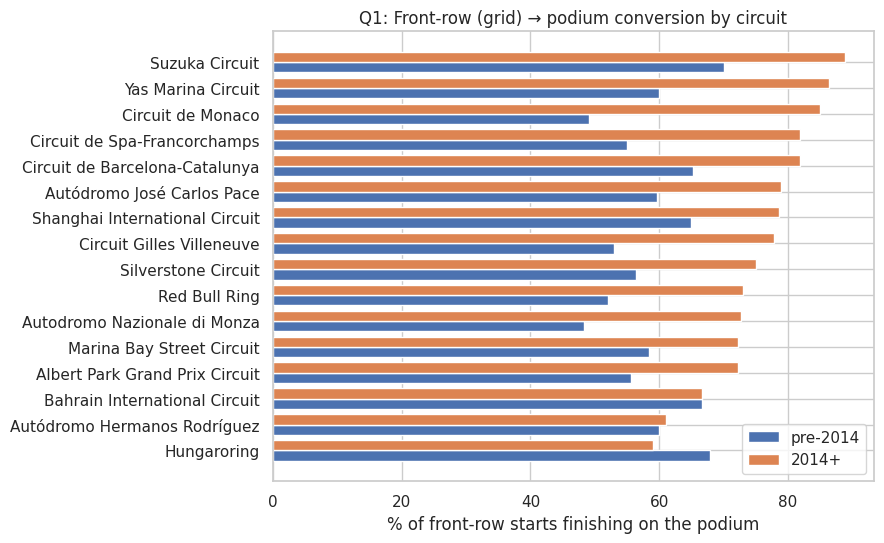

In [29]:
plot_df = q1_grid.sort_values("rate_2014+")
y = np.arange(len(plot_df))

plt.figure(figsize=(9, max(4, 0.35 * len(plot_df))))
plt.barh(y - 0.2, plot_df["rate_pre"] * 100,   height=0.4, label="pre-2014")
plt.barh(y + 0.2, plot_df["rate_2014+"] * 100, height=0.4, label="2014+")
plt.yticks(y, plot_df.index)
plt.xlabel("% of front-row starts finishing on the podium")
plt.title("Q1: Front-row (grid) → podium conversion by circuit")
plt.legend(); plt.tight_layout(); plt.show()

### Q1 — Answer: front-row → podium conversion by circuit
**Answer:** After 2014 the best circuits for converting a front-row start into a podium are **Suzuka (89%)**, **Yas Marina (86%)** and **Monaco (85%)**,
followed by Barcelona and Spa (82%). **The ranking changes a lot after 2014:** only Suzuka (1st in both periods) and Barcelona (4th) keep their place.
Monaco rises from 15th to 3rd (+36 points), while the Hungaroring falls from 2nd to 16th (68% → 59%), Bahrain from 3rd to 14th and Mexico from 6th to 15th.

**Overall conversion rate:**
| Definition of front row | pre-2014 | 2014+ |
|---|---|---|
| Started P1–P2 (`results.grid`) | 56.3% | 76.0% |
| Qualified P1–P2 (`qualifying.position`) | 64.7% | 74.0% |

- **Qualifying vs grid:** the two definitions disagree in **72 of 1,022** front-row rows with qualifying data (7%), because grid penalties move drivers
  off (or onto) the front row. The circuit rankings are similar under both definitions (Suzuka 1st in both, Hungaroring and Bahrain fall in both).
- **Why conversion rose after 2014:** cars became far more reliable, so front-row starters break down less often (see Q3), and the hybrid era was dominated by
  very few teams that also started at the front.
- **Why Monaco jumped:** overtaking there is almost impossible, so once cars stopped breaking down, a front-row start became close to a guaranteed podium.
  Its 120 pre-2014 front-row starts include many unreliable early decades.

**How we answered it:** `results` (grid, podium) + `qualifying` (position) + `races` (year) + `circuits` (name). A circuit is ranked only with
**≥ 10 front-row starts in both periods**, so one lucky race cannot produce 100% (16 circuits qualify for the grid definition, 14 for qualifying).

**Grain:** one row per driver per race (deduplicated); each race contributes at most two front-row starters. Indy 500 and non-starters excluded.
**Missingness:** the qualifying definition only covers years with qualifying records (complete from 2003), so its "pre-2014" sample is much smaller
and more modern than the grid one; this is why its pre-2014 rate is higher (64.7% vs 56.3%), and the two pre-2014 numbers are not like for like.
**Pre-race cutoff:** grid and qualifying position are known before the race; the podium is the outcome being measured.
**Caveats:** after 2014 a high rate partly reflects **team dominance** (Mercedes, then Red Bull) rather than the circuit itself; and with only 14–26
front-row starts per circuit after 2014, a single result changes a circuit's rate by about 4–7 points. 
**Sprint weekends:** in 2021–2022 Friday qualifying set the sprint grid and the sprint result set the Sunday grid, so part of the qualifying-vs-grid disagreement in those seasons comes from sprint results rather than penalties.

In [30]:
# Driver nationality (demonym) → country name as used in circuits.country
NAT_TO_COUNTRY = {
    "British": "UK", "English": "UK", "Scottish": "UK", "Welsh": "UK", "Northern Irish": "UK",
    "German": "Germany", "East German": "Germany", "West German": "Germany",
    "Italian": "Italy", "French": "France", "Spanish": "Spain", "Portuguese": "Portugal",
    "Belgian": "Belgium", "Dutch": "Netherlands", "Swiss": "Switzerland", "Austrian": "Austria",
    "Swedish": "Sweden", "Hungarian": "Hungary", "Monegasque": "Monaco", "Russian": "Russia",
    "Turkish": "Turkey", "American": "USA", "Canadian": "Canada", "Mexican": "Mexico",
    "Brazilian": "Brazil", "Argentine": "Argentina", "Argentinian": "Argentina",
    "Australian": "Australia", "Japanese": "Japan", "Chinese": "China", "Malaysian": "Malaysia",
    "Singaporean": "Singapore", "Indian": "India", "Korean": "Korea", "South African": "South Africa",
    "Moroccan": "Morocco", "Bahraini": "Bahrain", "Saudi": "Saudi Arabia", "Qatari": "Qatar",
    "Azerbaijani": "Azerbaijan", "Emirati": "UAE",
}
# Different spellings of the same country on the circuit side
COUNTRY_ALIASES = {"United States": "USA", "United Kingdom": "UK", "Great Britain": "UK",
                   "United Arab Emirates": "UAE", "South Korea": "Korea"}

drv = clean["drivers"][["driverId", "nationality"]].copy()
drv["home_country"] = drv["nationality"].map(NAT_TO_COUNTRY)
circ_c = clean["circuits"][["circuitId", "country"]].copy()
circ_c["circuit_country"] = circ_c["country"].replace(COUNTRY_ALIASES)

h = (base.merge(drv, on="driverId")
         .merge(circ_c[["circuitId", "circuit_country"]], on="circuitId"))
h["home"] = (h["home_country"] == h["circuit_country"]).astype(int)

# --- Mapping audit: prove the mapping didn't silently miss anything ---
circuit_countries = set(circ_c["circuit_country"].dropna())
print("Nationalities NOT in the mapping (these drivers can never be 'home'):")
print(drv.loc[drv["home_country"].isna(), "nationality"].value_counts().to_string(), "\n")
print("Mapped countries with no circuit (fine if the country never hosted a race):",
      sorted(set(NAT_TO_COUNTRY.values()) - circuit_countries))
print("Circuit countries with no mapped driver nationality:",
      sorted(circuit_countries - set(drv["home_country"].dropna())))
print(f"\nHome rows: {h['home'].sum()} of {len(h)} ({h['home'].mean():.1%})")

Nationalities NOT in the mapping (these drivers can never be 'home'):
nationality
New Zealander        10
Finnish               9
Danish                5
Irish                 5
Rhodesian             4
Uruguayan             4
Colombian             3
Venezuelan            3
Thai                  2
Chilean               1
Czech                 1
Polish                1
Liechtensteiner       1
American-Italian      1
Argentine-Italian     1
Indonesian            1
Argentinian           1 

Mapped countries with no circuit (fine if the country never hosted a race): []
Circuit countries with no mapped driver nationality: ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE']

Home rows: 1943 of 24724 (7.9%)


In [31]:
bins   = [0, 1, 3, 6, 10, 15, np.inf]
labels = ["1", "2-3", "4-6", "7-10", "11-15", "16+"]
h["grid_bucket"] = pd.cut(h["grid"], bins=bins, labels=labels)

tab = h.groupby(["grid_bucket", "home"], observed=True)["podium"].agg(["size", "mean"]).unstack("home")
q2 = pd.DataFrame({
    "away_starts": tab["size"][0], "home_starts": tab["size"][1],
    "away_rate":   tab["mean"][0], "home_rate":   tab["mean"][1],
})
q2["difference"] = q2["home_rate"] - q2["away_rate"]
display(q2.style.format({"away_rate": "{:.1%}", "home_rate": "{:.1%}", "difference": "{:+.1%}"}))

raw_diff = h.loc[h["home"] == 1, "podium"].mean() - h.loc[h["home"] == 0, "podium"].mean()
adj_diff = np.average(q2["difference"], weights=q2["home_starts"])
print(f"Raw difference (home − away), ignoring grid:      {raw_diff:+.1%}")
print(f"Difference within similar grid positions:          {adj_diff:+.1%}")

,away_starts,home_starts,away_rate,home_rate,difference
grid_bucket,,,,,
1,1032,81,64.7%,60.5%,-4.2%
2-3,2074,148,51.0%,55.4%,+4.4%
4-6,3108,225,26.1%,27.1%,+1.0%
7-10,4124,337,9.3%,7.4%,-1.9%
11-15,5136,414,3.0%,2.7%,-0.3%
16+,7307,738,0.7%,0.3%,-0.5%


Raw difference (home − away), ignoring grid:      -1.9%
Difference within similar grid positions:          -0.3%


All years    odds ratio for home = 0.96 (95% CI 0.81–1.14), p = 0.647, rows = 24724
2003+        odds ratio for home = 0.76 (95% CI 0.51–1.13), p = 0.177, rows = 8956


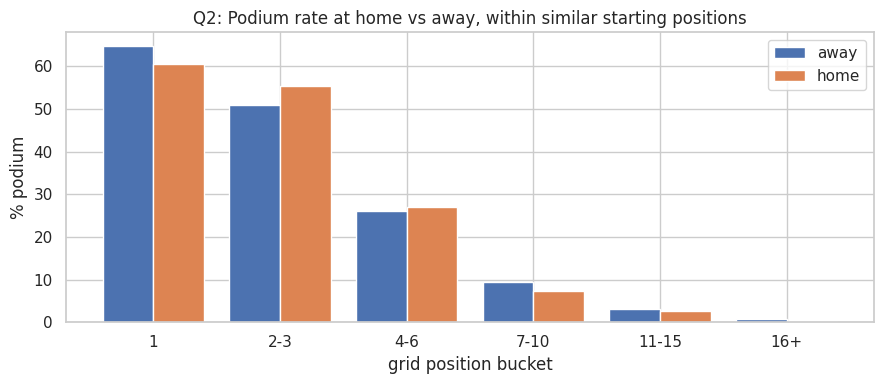

In [32]:
import statsmodels.formula.api as smf

def home_effect(df, label):
    m = smf.logit("podium ~ home + C(grid_bucket)", data=df).fit(disp=0)
    ci = np.exp(m.conf_int().loc["home"])
    print(f"{label:12s} odds ratio for home = {np.exp(m.params['home']):.2f} "
          f"(95% CI {ci[0]:.2f}–{ci[1]:.2f}), p = {m.pvalues['home']:.3f}, rows = {len(df)}")

home_effect(h, "All years")
home_effect(h[h["year"] >= 2003], "2003+")      # robustness check on the modern era

x = np.arange(len(q2))
plt.figure(figsize=(9, 4))
plt.bar(x - 0.2, q2["away_rate"] * 100, width=0.4, label="away")
plt.bar(x + 0.2, q2["home_rate"] * 100, width=0.4, label="home")
plt.xticks(x, q2.index); plt.xlabel("grid position bucket"); plt.ylabel("% podium")
plt.title("Q2: Podium rate at home vs away, within similar starting positions")
plt.legend(); plt.tight_layout(); plt.show()

### Q2 — Answer: home advantage
**Answer:** **No home advantage.** Comparing drivers who started from similar grid positions, home drivers podium **0.3 percentage points less** often
than away drivers, and the logistic regression `podium ~ home + grid bucket` gives an **odds ratio of 0.96 (95% CI 0.81–1.14, p = 0.65)**.
The interval includes 1.0, so the effect is not distinguishable from zero. On 2003+ only: odds ratio 0.76 (95% CI 0.51–1.13, p = 0.18), also not significant.

| Grid bucket | Away podium rate | Home podium rate | Difference |
|---|---|---|---|
| 1 | 64.7% | 60.5% | −4.2% |
| 2–3 | 51.0% | 55.4% | +4.4% |
| 4–6 | 26.1% | 27.1% | +1.0% |
| 7–10 | 9.3% | 7.4% | −1.9% |
| 11–15 | 3.0% | 2.7% | −0.3% |
| 16+ | 0.7% | 0.3% | −0.5% |

- **The naive comparison is misleading:** ignoring grid, home drivers podium 1.9 points *less* often. That is because many home entries, especially in
  older races, were local one-off drivers in weak cars who started further back. Once the grid is held fixed, the gap shrinks to −0.3 points.
- **Within the grid buckets the sign changes** (worse from pole, better from P2–3), so there is no consistent pattern.
- Only 7.9% of rows (1,943 of 24,724) are home races, so each bucket's home rate rests on 81–738 starts.

**How we answered it:** `results` → `drivers` (nationality) and `races` → `circuits` (country). Nationalities were mapped to circuit countries by hand
(e.g. British → UK, Monegasque → Monaco, East German → Germany), and spellings of the same country on the circuit side were merged ("United States"/"USA").
**Grain:** one row per driver per race; Indy 500 and non-starters excluded.
**Missingness:** drivers from countries that never hosted a race (e.g. New Zealander, Finnish, Danish) can never be "home" and stay in the data as away rows.
**Pre-race cutoff:** nationality, circuit and grid are known before the race; the podium is the outcome.
**Implication for modeling:** `is_home` was therefore **not used as a model feature** (Section 8).

In [33]:
# Car-component failures (matched as text inside the status, case-insensitive)
MECH_PATTERNS = [
    "engine", "gearbox", "transmission", "clutch", "hydraulic", "electric", "radiator", "suspension",
    "brake", "differential", "overheat", "mechanical", "power unit", "turbo", "fuel", "oil", "water",
    "throttle", "steering", "exhaust", "driveshaft", "halfshaft", "axle", "battery", r"\bers\b",
    "power loss", "vibration", "spark", "pneumatic", "cooling", "pump", "injection", "ignition",
    "alternator", "magneto", "crankshaft", "piston", "valve", "wheel bearing", "drivetrain",
    "technical", "distributor", "launch control", 
]
# Not a component failure: crash, driver, regulation, or unclear cause. These override the list above.
EXCLUDE_PATTERNS = [
    "driver", "collision", "accident", "spun", "disqualified", "excluded", "damage", "debris",
    "puncture", "tyre", "wheel nut", "out of fuel", "fuel rig", "illness", "injur", "withdrew",
    "did not", "underweight", "safety", "physical", "fatal", "not classified", "retired", "handling",
]

st = clean["status"].copy()
s = st["status"].str.lower()
st["mechanical"] = (s.str.contains("|".join(MECH_PATTERNS), regex=True)
                    & ~s.str.contains("|".join(EXCLUDE_PATTERNS), regex=True))

cons = clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"})
r3 = (base[base["year"] >= 2014]
      .merge(st, on="statusId")
      .merge(cons, on="constructorId"))
r3["period"] = np.where(r3["year"] <= 2021, "2014-2021", "2022-2024")

# Review table: every non-finish status in 2014–2024 and how we labelled it
not_finished = ~(r3["status"].eq("Finished") | r3["status"].str.startswith("+"))
review = (r3[not_finished].groupby(["mechanical", "status"]).size().rename("count")
            .reset_index().sort_values(["mechanical", "count"], ascending=[False, False]))
display(review)

,mechanical,status,count
31,True,Engine,80
23,True,Brakes,48
36,True,Gearbox,42
42,True,Power Unit,42
47,True,Suspension,25
37,True,Hydraulics,15
30,True,Electrical,14
43,True,Power loss,13
39,True,Oil leak,10
41,True,Overheating,8


Overall mechanical-retirement rate per period:
period
2014-2021    9.0%
2022-2024    5.6%
Name: mechanical, dtype: object 



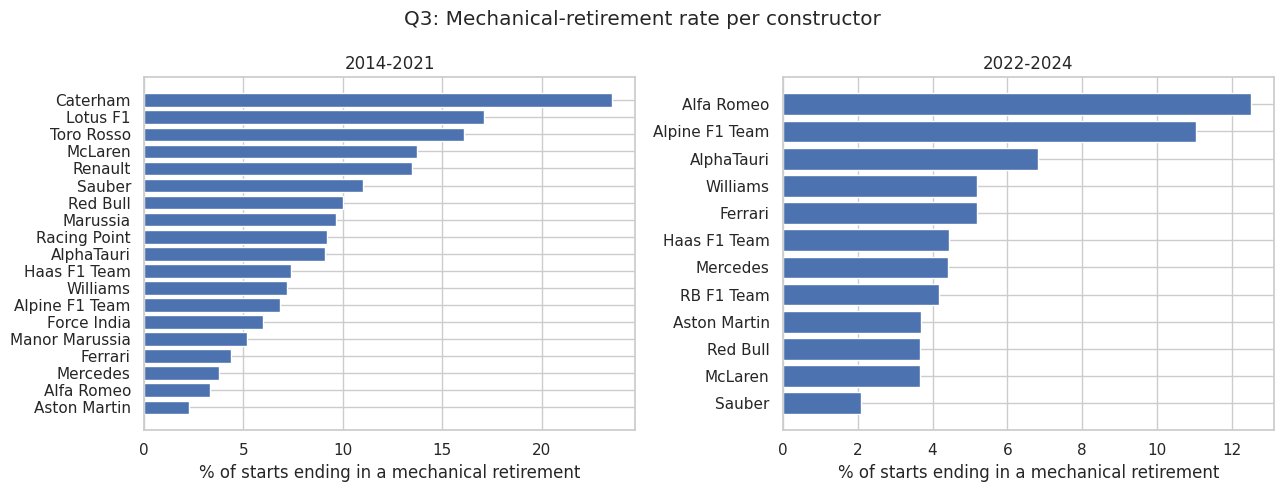


Top 5, 2014-2021:


period,constructor,starts,mech_dnf,rate
2014-2021,Caterham,34,8,23.5%
2014-2021,Lotus F1,76,13,17.1%
2014-2021,Toro Rosso,242,39,16.1%
2014-2021,McLaren,320,44,13.8%
2014-2021,Renault,200,27,13.5%



Top 5, 2022-2024:


period,constructor,starts,mech_dnf,rate
2022-2024,Alfa Romeo,88,11,12.5%
2022-2024,Alpine F1 Team,136,15,11.0%
2022-2024,AlphaTauri,88,6,6.8%
2022-2024,Ferrari,135,7,5.2%
2022-2024,Williams,135,7,5.2%


In [34]:
MIN_STARTS_Q3 = 20   # ≈ half a season for a 2-car team, so tiny samples can't top the list

rates = (r3.groupby(["period", "constructor"])
           .agg(starts=("mechanical", "size"), mech_dnf=("mechanical", "sum")))
rates["rate"] = rates["mech_dnf"] / rates["starts"]
rates = rates[rates["starts"] >= MIN_STARTS_Q3].reset_index()

print("Overall mechanical-retirement rate per period:")
print((r3.groupby("period")["mechanical"].mean() * 100).round(1).astype(str) + "%", "\n")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, period in zip(axes, ["2014-2021", "2022-2024"]):
    d = rates[rates["period"] == period].sort_values("rate")
    ax.barh(d["constructor"], d["rate"] * 100)
    ax.set_title(f"{period}"); ax.set_xlabel("% of starts ending in a mechanical retirement")
fig.suptitle("Q3: Mechanical-retirement rate per constructor"); plt.tight_layout(); plt.show()

for period in ["2014-2021", "2022-2024"]:
    print(f"\nTop 5, {period}:")
    display(rates[rates["period"] == period].nlargest(5, "rate")
            .style.format({"rate": "{:.1%}"}).hide(axis="index"))

### Q3 — Answer: mechanical-retirement rate per constructor
**Answer:** Cars broke down much less often in the new era: the mechanical-retirement rate fell from **9.0% of starts (2014–2021)** to **5.6% (2022–2024)**.

| Rank | 2014–2021 | Rate (starts) | 2022–2024 | Rate (starts) |
|---|---|---|---|---|
| 1 | Caterham | 23.5% (34) | Alfa Romeo | 12.5% (88) |
| 2 | Lotus F1 | 17.1% (76) | Alpine F1 Team | 11.0% (136) |
| 3 | Toro Rosso | 16.1% (242) | AlphaTauri | 6.8% (88) |
| 4 | McLaren | 13.8% (320) | Ferrari | 5.2% (135) |
| 5 | Renault | 13.5% (200) | Williams | 5.2% (135) |

- 2014–2021 is led by small or struggling teams (Caterham, Lotus F1) and by teams whose engines were unreliable early in the hybrid era
  (McLaren's Honda years, Renault-powered teams). In 2022–2024 the worst rate (12.5%) is lower than five teams' rates before.
- Teams that changed name appear under different names in the two periods (e.g. Toro Rosso → AlphaTauri, Renault → Alpine), so the two lists are
  separate rankings rather than a team-by-team comparison.

**Definition (from the brief):** a race **start** that ended early because a **car component failed**; failures caused by a crash, the driver or a
regulation decision are excluded. Each `status` was labelled with a keyword rule; the full list of statuses and labels is shown in the review table above.
- **Mechanical:** engine, power unit, gearbox, brakes, suspension, hydraulics, electrical, oil/water leaks, overheating, turbo, ERS, …
- **Not mechanical:** collision, accident, spun off, disqualified, withdrew, illness (crash, driver or regulation).
- **Excluded as unclear:** "Retired" (cause unknown, 50 starts), puncture/tyre/wheel (often debris), wheel nut (pit-stop error), front/rear wing and
  undertray (usually crash damage), out of fuel (strategy).

**How we answered it:** `results` + `status` (label) + `constructors` (name) + `races` (year). Rate = mechanical retirements ÷ race starts;
only constructors with **≥ 20 starts** in a period are ranked.
**Grain:** one row per driver per race start (non-starters already removed, so the denominator is starts, not entries).
**Missingness / labelling:** "Retired" with no cause is excluded, so rates may be slightly **underestimated**. Our keyword rule also left 4 "Electronics"
retirements as non-mechanical although they are component failures, so those 4 starts are not counted (the same labels feed the `team_mech_rate_last10` feature).
**Pre-race cutoff:** status is **post-race** information. That is fine for this analysis, but the reliability **feature** used by the model
(`team_mech_rate_last10`) is computed from **past races only**.

## 8. Feature engineering & selection
Every feature must be (a) known before the race, (b) justified with a plot or statistic.

Candidate groups: **grid**, **qualifying** (position, gap to pole), **driver form** (past races only),
**constructor form** (past races only), **standings before this race** (shifted by one race).

In [35]:
# ===== 8.1 Chronological order + previous race in the same season =====
races_o = clean["races"][["raceId", "year", "round"]].sort_values(["year", "round"]).copy()
races_o["prev_raceId"] = races_o.groupby("year")["raceId"].shift(1).astype("Int64")
races_o["race_seq"] = np.arange(len(races_o))

df = (base.merge(races_o[["raceId", "prev_raceId", "race_seq"]], on="raceId")
          .sort_values(["race_seq", "grid"]).reset_index(drop=True))

# ===== 8.2 Grid features =====
df["field_size"] = df.groupby("raceId")["driverId"].transform("size")
df["grid_rel"]   = df["grid"] / df["field_size"]
df["front_row"]  = (df["grid"] <= 2).astype(int)

# ===== 8.3 Qualifying features =====
q = clean["qualifying"][["raceId", "driverId", "position", "q1_s", "q2_s", "q3_s"]].rename(columns={"position": "quali_pos"})
q["best_q_s"] = q[["q1_s", "q2_s", "q3_s"]].min(axis=1)
pole_time = q.groupby("raceId")["best_q_s"].transform("min")
q["gap_to_pole_pct"] = (q["best_q_s"] - pole_time) / pole_time * 100
df = df.merge(q[["raceId", "driverId", "quali_pos", "gap_to_pole_pct"]], on=["raceId", "driverId"], how="left")
df["has_quali"]        = df["quali_pos"].notna().astype(int)
df["grid_minus_quali"] = df["grid"] - df["quali_pos"]

# ===== 8.4 Form features (PAST races only: shift(1) excludes the current race) =====
df = df.sort_values(["race_seq", "grid"]).reset_index(drop=True)
g = df.groupby("driverId")
df["drv_races_before"]      = g.cumcount()
df["drv_podium_rate_last5"] = g["podium"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df["drv_avg_finish_last5"]  = g["positionOrder"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

df = df.merge(st[["statusId", "mechanical"]], on="statusId", how="left")
team_race = (df.groupby(["constructorId", "raceId", "race_seq"], as_index=False)
               .agg(team_podiums=("podium", "sum"), team_best=("positionOrder", "min"),
                    team_mech=("mechanical", "sum"), team_starts=("mechanical", "size"))
               .sort_values("race_seq"))
tg = team_race.groupby("constructorId")
team_race["team_podiums_last5"]     = tg["team_podiums"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum())
team_race["team_best_finish_last5"] = tg["team_best"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
mech_sum   = tg["team_mech"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())
starts_sum = tg["team_starts"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())
team_race["team_mech_rate_last10"]  = mech_sum / starts_sum
df = df.merge(team_race[["constructorId", "raceId", "team_podiums_last5", "team_best_finish_last5",
                         "team_mech_rate_last10"]], on=["constructorId", "raceId"], how="left")

# ===== 8.5 Championship standings BEFORE the race (= standings after the previous round) =====
ds = clean["driver_standings"][["raceId", "driverId", "points", "wins"]].rename(
        columns={"raceId": "prev_raceId", "points": "drv_pts_before", "wins": "drv_wins_before"})
ds["prev_raceId"] = ds["prev_raceId"].astype("Int64")
ds["leader"] = ds.groupby("prev_raceId")["drv_pts_before"].transform("max")
ds["drv_pts_share"] = np.where(ds["leader"] > 0, ds["drv_pts_before"] / ds["leader"], 0.0)

cs = clean["constructor_standings"][["raceId", "constructorId", "points", "wins"]].rename(
        columns={"raceId": "prev_raceId", "points": "con_pts_before", "wins": "con_wins_before"})
cs["prev_raceId"] = cs["prev_raceId"].astype("Int64")
cs["leader"] = cs.groupby("prev_raceId")["con_pts_before"].transform("max")
cs["con_pts_share"] = np.where(cs["leader"] > 0, cs["con_pts_before"] / cs["leader"], 0.0)

df = (df.merge(ds[["prev_raceId", "driverId", "drv_pts_share", "drv_wins_before"]], on=["prev_raceId", "driverId"], how="left")
        .merge(cs[["prev_raceId", "constructorId", "con_pts_share", "con_wins_before"]], on=["prev_raceId", "constructorId"], how="left"))
# Round 1, or no standings entry yet = 0 points and 0 wins so far this season (true, not a guess)
for c in ["drv_pts_share", "drv_wins_before", "con_pts_share", "con_wins_before"]:
    df[c] = df[c].fillna(0)

# ===== 8.6 Home race (mapping from Q2) =====
df = (df.merge(drv[["driverId", "home_country"]], on="driverId", how="left")
        .merge(circ_c[["circuitId", "circuit_country"]], on="circuitId", how="left"))
df["is_home"] = (df["home_country"] == df["circuit_country"]).astype(int)

### 8.1b Qualifying fills (flags first, then same-race fills)
- `has_quali` = the driver has a qualifying record; `no_quali_time` = he has a record but set **no lap time** (crash, mechanical failure).
  Both flags are created **before** filling, so the model still knows which values were filled.
- A driver with no lap time effectively qualified **last**, so his gap to pole is set to the **slowest gap in that race**.
  Filling with the training median would wrongly make him look like a midfield qualifier.
- Rows with no qualifying record at all get `quali_pos = grid` (the grid is normally the qualifying order).
- Both rules use only information from the same race, which is known before the start, so they cannot leak.

In [36]:
# ===== 8.3b Qualifying fills (flags FIRST, then fill using the same race only) =====
df["has_quali"]     = df["quali_pos"].notna().astype(int)                          # any qualifying record
df["no_quali_time"] = (df["has_quali"].eq(1) & df["gap_to_pole_pct"].isna()).astype(int)  # record but no lap time

# No lap time = effectively qualified last → give him the slowest gap set in that race
slowest_gap = df.groupby("raceId")["gap_to_pole_pct"].transform("max")
df["gap_to_pole_pct"] = df["gap_to_pole_pct"].fillna(slowest_gap)   # covers both: no lap time AND no record
# No qualifying record at all → qualifying position = grid position (grid is set by qualifying)
df["quali_pos"] = df["quali_pos"].fillna(df["grid"])
df["grid_minus_quali"] = df["grid"] - df["quali_pos"]
print(f"Rows with a qualifying record but no lap time: {df['no_quali_time'].sum()}")
print(f"Rows with no qualifying record (quali_pos filled with grid): {(df['has_quali'] == 0).sum()}")

Rows with a qualifying record but no lap time: 155
Rows with no qualifying record (quali_pos filled with grid): 14246


### 8.1c Team lineage
Each team **name** has its own `constructorId`, which breaks team-form features in two opposite ways:
- **Same team, new name → history wrongly erased.** e.g. Racing Point → Aston Martin (same Silverstone factory and staff).
- **Same name re-used by an unrelated team decades later → wrong history glued on.** e.g. "Mercedes" (ID 131) raced in 1954–55
  and again from 2010, so Mercedes' first race in 2010 took its "last 5 races" from 1955. Same for Aston Martin (1959–60 / 2021+),
  Alfa Romeo (to 1985 / 2019+), Honda (1964–68 / 2006+), Renault (1977–85 / 2002+).

**Fix:** a `team_lineage` column that follows the actual team (same factory and staff) through its renames.
- The mapping uses **name + season**, so e.g. "Mercedes" only joins the Mercedes line from 2010; the 1950s rows stay a separate team.
- **Safety net:** any team not in the table keeps its own ID, but its history **restarts after more than one season without racing**,
  so re-used IDs are split automatically even if they were missed in the table.
- The code stops if a name is misspelled, and prints each chain's seasons and the list of unmapped teams for review.

In [37]:
# ===== 8.4b Team lineage: follow the real team through renames (table from our lineage plan) =====
# (name in constructors.csv, first season, last season) — None = open-ended
LINEAGE = {
    "Aston Martin line":    [("Jordan", None, 2005), ("MF1", 2006, 2006), ("Spyker MF1", 2006, 2006),
                             ("Spyker", 2007, 2007), ("Force India", 2008, 2018),
                             ("Racing Point", 2019, 2020), ("Aston Martin", 2021, None)],
    "Red Bull line":        [("Jaguar", None, 2004), ("Red Bull", 2005, None)],
    "Junior Red Bull line": [("Minardi", None, 2005), ("Toro Rosso", 2006, 2019),
                             ("AlphaTauri", 2020, 2023), ("RB F1 Team", 2024, None)],
    "Mercedes line":        [("BAR", None, 2005), ("Honda", 2006, 2008), ("Brawn", 2009, 2009),
                             ("Mercedes", 2010, None)],
    "Alpine line":          [("Benetton", None, 2001), ("Renault", 2002, None), ("Lotus F1", 2012, 2015),
                             ("Alpine F1 Team", 2021, None)],
    "Sauber line":          [("Sauber", None, None), ("BMW Sauber", 2006, 2009), ("Alfa Romeo", 2019, 2023)],
    "Caterham line":        [("Lotus", 2010, 2011), ("Caterham", 2012, 2014)],
    "Manor line":           [("Virgin", 2010, 2011), ("Marussia", 2012, 2014), ("Manor Marussia", 2015, 2016)],
}

cons_names = clean["constructors"][["constructorId", "name"]].rename(columns={"name": "team_name"})
cy = df[["constructorId", "year"]].drop_duplicates().merge(cons_names, on="constructorId")
cy["team_lineage"] = pd.Series(pd.NA, index=cy.index, dtype="object")

for line, members in LINEAGE.items():
    for name, y0, y1 in members:
        assert name in set(cons_names["team_name"]), f"'{name}' is not a name in constructors.csv — check spelling"
        m = (cy["team_name"] == name) & cy["year"].between(y0 or 0, y1 or 9999)
        assert m.any(), f"'{name}' has no races between {y0} and {y1}"
        cy.loc[m, "team_lineage"] = line

# Every other team keeps its own ID, but its history restarts if it did not race for more than one season.
# This automatically splits re-used IDs (e.g. Mercedes 1955 vs 2010) even if they were not in the table.
cy = cy.sort_values(["constructorId", "year"])
new_spell = cy.groupby("constructorId")["year"].diff().gt(1)
cy["spell"] = new_spell.groupby(cy["constructorId"]).cumsum()
other = cy["team_lineage"].isna()
cy.loc[other, "team_lineage"] = ("id" + cy.loc[other, "constructorId"].astype(str)
                                 + "_spell" + cy.loc[other, "spell"].astype(str))

df = df.drop(columns=["team_lineage"], errors="ignore").merge(
        cy[["constructorId", "year", "team_lineage"]], on=["constructorId", "year"], how="left")

# Check 1: a lineage never has two different constructorIds in the same race
assert df.groupby(["raceId", "team_lineage"])["constructorId"].nunique().max() == 1, "two teams merged in one race"

# Check 2: show each chain with the seasons each name actually raced (they should follow each other)
chains = (cy[~cy["team_lineage"].str.startswith("id")]
          .groupby(["team_lineage", "team_name"])["year"].agg(["min", "max"])
          .sort_values(["team_lineage", "min"]))
display(chains)

# Check 3: teams racing from 2003 that are NOT in any chain (should only be teams that never changed name)
unchanged = cy[(cy["year"] >= 2003) & cy["team_lineage"].str.startswith("id")]["team_name"].unique()
print("Teams from 2003 not in any chain (expected: unchanged teams):", sorted(unchanged))

min   max
team_lineage         team_name                 
Alpine line          Benetton        1986  2001
                     Renault         2002  2020
                     Lotus F1        2012  2015
                     Alpine F1 Team  2021  2024
Aston Martin line    Jordan          1991  2005
                     MF1             2006  2006
                     Spyker MF1      2006  2006
                     Spyker          2007  2007
                     Force India     2008  2018
                     Racing Point    2019  2020
                     Aston Martin    2021  2024
Caterham line        Lotus           2010  2011
                     Caterham        2012  2014
Junior Red Bull line Minardi         1985  2005
                     Toro Rosso      2006  2019
                     AlphaTauri      2020  2023
                     RB F1 Team      2024  2024
Manor line           Virgin          2010  2011
                     Marussia        2012  2014
                     Manor Marussia  2015  2016
Mercedes line        BAR             1999  2005
                     Honda           2006  2008
                     Brawn           2009  2009
                     Mercedes        2010  2024
Red Bull line        Jaguar          2000  2004
                     Red Bull        2005  2024
Sauber line          Sauber          1993  2024
                     BMW Sauber      2006  2009
                     Alfa Romeo      2019  2023

Teams from 2003 not in any chain (expected: unchanged teams): ['Ferrari', 'HRT', 'Haas F1 Team', 'McLaren', 'Super Aguri', 'Toyota', 'Williams']


In [38]:
# ===== 8.4c Team form, computed two ways (by lineage = used; by constructorId = kept for comparison) =====
def team_form(key):
    tr = (df.groupby([key, "raceId", "race_seq"], as_index=False)
            .agg(team_podiums=("podium", "sum"), team_best=("positionOrder", "min"),
                 team_mech=("mechanical", "sum"), team_starts=("mechanical", "size"))
            .sort_values("race_seq"))
    g = tr.groupby(key)
    out = tr[[key, "raceId"]].copy()
    out["team_podiums_last5"]     = g["team_podiums"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum())
    out["team_best_finish_last5"] = g["team_best"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    mech   = g["team_mech"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())
    starts = g["team_starts"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())
    out["team_mech_rate_last10"]  = mech / starts
    return out

TEAM_COLS = ["team_podiums_last5", "team_best_finish_last5", "team_mech_rate_last10"]
df = df.drop(columns=TEAM_COLS + [c + "_byid" for c in TEAM_COLS], errors="ignore")
df = df.merge(team_form("team_lineage"), on=["team_lineage", "raceId"], how="left")
by_id = team_form("constructorId").rename(columns={c: c + "_byid" for c in TEAM_COLS})
df = df.merge(by_id, on=["constructorId", "raceId"], how="left")

# Before / after evidence: each team's first race under a new name
cases = [("Brawn", 2009), ("Mercedes", 2010), ("Aston Martin", 2021), ("Alpine F1 Team", 2021), ("Haas F1 Team", 2016)]
rows = []
for name, yr in cases:
    ids = cons_names.loc[cons_names["team_name"] == name, "constructorId"]
    first = df[df["constructorId"].isin(ids) & (df["year"] == yr)]
    if len(first):
        r = first.loc[first["race_seq"].idxmin()]
        rows.append({"team": name, "first race of": yr,
                     "podiums last 5 — by ID (before)":   r["team_podiums_last5_byid"],
                     "podiums last 5 — by lineage (after)": r["team_podiums_last5"]})
display(pd.DataFrame(rows))

,team,first race of,podiums last 5 — by ID (before),podiums last 5 — by lineage (after)
0,Brawn,2009,NaN,0.0
1,Mercedes,2010,9.0,3.0
2,Aston Martin,2021,0.0,3.0
3,Alpine F1 Team,2021,NaN,2.0
4,Haas F1 Team,2016,NaN,NaN


**Team-form features now follow `team_lineage`** (`team_podiums_last5`, `team_best_finish_last5`, `team_mech_rate_last10`).
The old by-`constructorId` versions are kept as `*_byid` columns (not used as features) for the before/after table above and for a Section 11 comparison.
Standings features are unchanged: they reset every season and renames happen between seasons.

**Limitations of the lineage approach:**
- Lineage is a judgement call. Our rule is "same factory and staff"; a new owner with a new budget could be argued to be a different team.
- Carrying form across a winter assumes the team stays about as good. Brawn shows the limit (Honda was poor in late 2008, Brawn won in 2009),
  but the model already makes this assumption for every unchanged team at each season start, so it is consistent.
- The effect on scores is expected to be small (only each team's first few races after a rename change); it is mainly a correctness fix.
- The chains cover the teams racing around 2000 onwards; older renames (e.g. Toleman → Benetton, Tyrrell → BAR, Stewart → Jaguar)
  are only handled by the one-season-gap rule, which matters for the all-years option only.

In [39]:
# ===== 8.7 Assemble the modeling table + leakage checks =====
FEATURE_GROUPS = {
    "grid":             ["grid", "grid_rel", "front_row", "pit_lane_start", "field_size"],
    "qualifying":       ["quali_pos", "gap_to_pole_pct", "grid_minus_quali", "has_quali", "no_quali_time"],
    "driver_form":      ["drv_podium_rate_last5", "drv_avg_finish_last5", "drv_races_before"],
    "constructor_form": ["team_podiums_last5", "team_best_finish_last5", "team_mech_rate_last10"],
    "standings":        ["drv_pts_share", "drv_wins_before", "con_pts_share", "con_wins_before"],
}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]
ID_COLS  = ["raceId", "driverId", "constructorId", "year", "round", "date"]

model_df = df[ID_COLS + FEATURES + ["podium"]].copy()

# Check 1: no post-race column is used as a feature
POST_RACE = ["positionOrder", "position", "positionText", "points", "laps", "time", "milliseconds",
             "fastestLap", "rank", "fastestLapTime", "fastestLapTime_s", "fastestLapSpeed", "statusId", "mechanical"]
assert not set(FEATURES) & set(POST_RACE), "post-race column used as a feature!"

# Check 2: one row per driver per race
assert not model_df.duplicated(["raceId", "driverId"]).any()

# Check 3: a driver's first race has no form (nothing in the past to compute it from)
assert df.loc[df["drv_races_before"] == 0, "drv_podium_rate_last5"].isna().all()

# Check 4: recompute the form feature by hand for random rows, using ONLY earlier races
rng = np.random.default_rng(SEED)
for i in rng.choice(df.index[df["drv_races_before"] >= 5], size=20, replace=False):
    row  = df.loc[i]
    past = df[(df["driverId"] == row["driverId"]) & (df["race_seq"] < row["race_seq"])].nlargest(5, "race_seq")
    assert np.isclose(past["podium"].mean(), row["drv_podium_rate_last5"]), f"form mismatch at row {i}"
print("Leakage checks passed ✅")

# Same two training-year versions as before, now with features
model_tables = {name: model_df[model_df["year"] >= start].copy() for name, start in YEAR_OPTIONS.items()}
print(f"model_df: {model_df.shape[0]} rows × {len(FEATURES)} features")

# Missing values per feature in the 2003+ version
miss = model_tables["from_2003"][FEATURES].isna().mean().mul(100).round(1)
display(miss[miss > 0].rename("% missing (2003+)").to_frame())

Leakage checks passed ✅
model_df: 24724 rows × 20 features


,% missing (2003+)
drv_podium_rate_last5,1.0
drv_avg_finish_last5,1.0
team_podiums_last5,0.1
team_best_finish_last5,0.1
team_mech_rate_last10,0.1


,spearman_with_podium,group
front_row,+0.53,grid
drv_podium_rate_last5,+0.53,driver_form
team_podiums_last5,+0.51,constructor_form
con_wins_before,+0.50,standings
quali_pos,-0.50,qualifying
grid,-0.49,grid
grid_rel,-0.49,grid
gap_to_pole_pct,-0.47,qualifying
drv_wins_before,+0.47,standings
team_best_finish_last5,-0.47,constructor_form


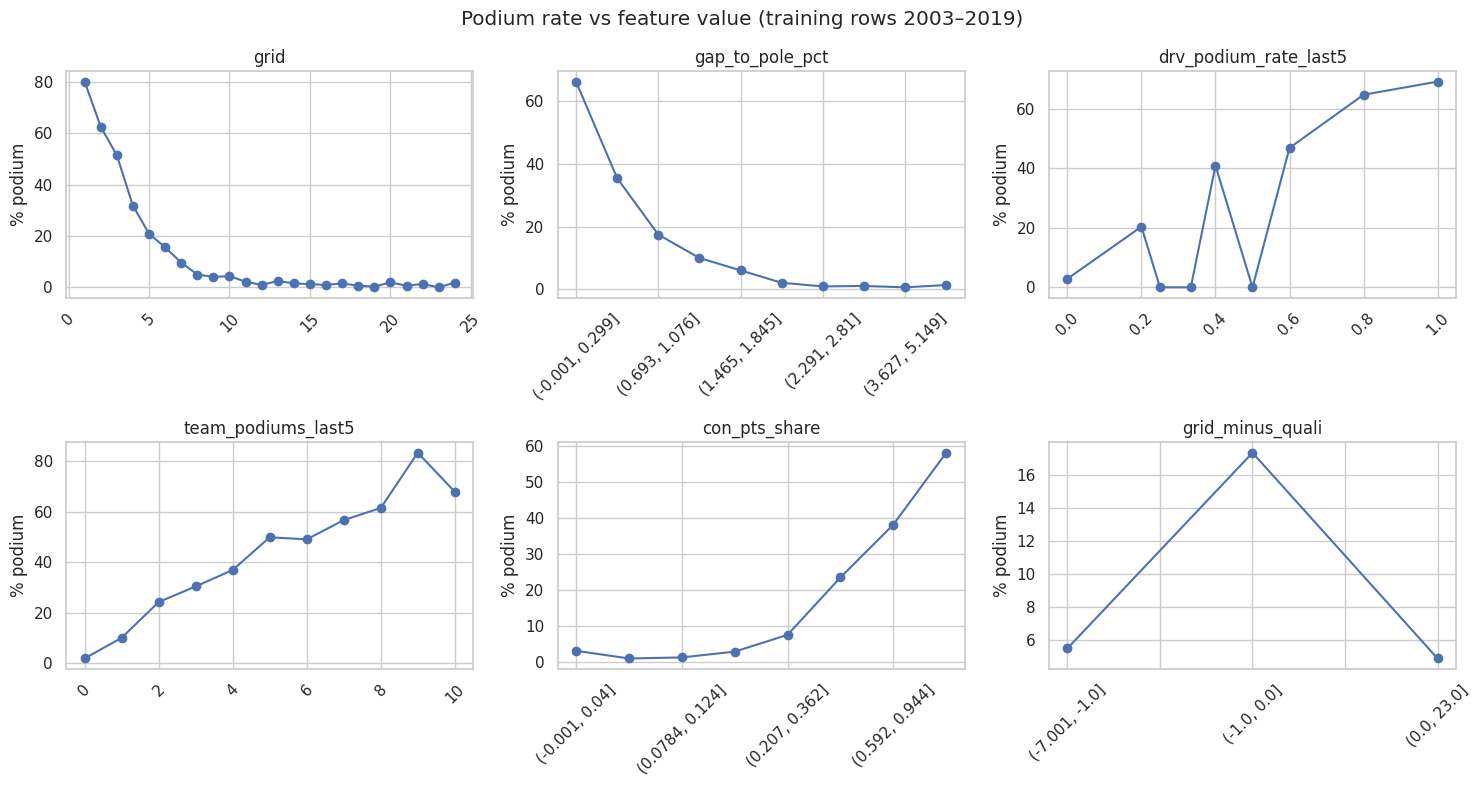

In [40]:
# ===== 8.8 Evidence for each feature (TRAINING years only, so validation/test stay unseen) =====
ev = model_tables["from_2003"]
ev = ev[ev["year"] <= TRAIN_END]

corr = (ev[FEATURES].corrwith(ev["podium"], method="spearman")
          .rename("spearman_with_podium").to_frame())
corr["group"] = [g for g, cols in FEATURE_GROUPS.items() for _ in cols]
display(corr.sort_values("spearman_with_podium", key=abs, ascending=False)
            .style.format({"spearman_with_podium": "{:+.2f}"}))

PLOT_FEATURES = ["grid", "gap_to_pole_pct", "drv_podium_rate_last5",
                 "team_podiums_last5", "con_pts_share", "grid_minus_quali"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), PLOT_FEATURES):
    x = ev[f]
    bins = x if x.nunique() <= 25 else pd.qcut(x, 10, duplicates="drop")
    rate = ev.groupby(bins, observed=True)["podium"].mean() * 100
    rate.plot(ax=ax, marker="o")
    ax.set_title(f); ax.set_ylabel("% podium"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Podium rate vs feature value (training rows 2003–2019)")
plt.tight_layout(); plt.show()

**Feature evidence (training rows 2003–2019 only, so validation and test stay unseen):**
- **Leakage-safe:** all form features use only earlier races (`shift(1)` before rolling); standings come from the previous round.
  Verified by recomputing the form feature by hand for 20 random rows using only earlier races.
- **Missing values are small and explained:** qualifying gaps are filled by same-race rules (8.1b); the remaining gaps are a driver's or
  team's first race (no past to compute form from). These are left as `NaN` here and imputed inside the model pipeline, fitted on the training set only.
- **Strong predictors (|Spearman| 0.43–0.53):** grid / front row, qualifying position and gap to pole, driver and team recent form,
  championship standings. The plots show the expected direction: podium rate falls steeply with grid position and gap to pole,
  and rises with recent form and team points.
- **`front_row` (+0.53) correlates more strongly than `grid` (−0.49)** because the relationship is non-linear: podium chances
  drop sharply after the first few grid slots.
- **Overlap:** grid, qualifying, form and standings all partly measure car performance, so their individual contributions are
  tested with an ablation in Section 11 rather than assumed from these correlations.
- **Weak features kept for now:** `pit_lane_start` and `grid_minus_quali` describe rare situations (penalties, pit-lane starts),
  so a low overall correlation does not rule them out; `has_quali` is near-constant from 2003 but needed for the all-years option.
  The ablation (11.1) showed they add ≤ 0.003 PR-AUC; they are kept because they are cheap and needed for the all-years option.
- **`no_quali_time`** flags the rare drivers who set no qualifying lap time, so the model knows their gap was filled.
- **Team form follows `team_lineage`** (8.1c), not the raw `constructorId`.
- **Excluded:** `is_home` (see Q2).
- **`grid_minus_quali` on sprint weekends (2021–2022)** reflects the sprint result rather than a penalty, because the sprint set the Sunday grid.

## 9. Train / validation / test split

| Set | Seasons | Role |
|---|---|---|
| Train | ≤ 2019 (from 2003 or from 1950, see decision 1) | Fit the models |
| Validation | 2020–2021 | Choose hyperparameters, decision threshold, training-year option and feature set |
| Test | 2022–2024 | Final evaluation, used **once** at the end |

**Why a time-based split instead of a random split:**
- **It mirrors real use.** The model's job is to predict future races from past ones. A random split would let the model
  train on 2023 races and be tested on 2018, i.e. learn from the future.
- **It keeps each race in one set.** With a random split, teammates from the same race could land in train and test,
  and the model would learn that specific race's conditions instead of general patterns.
- **The form and standings features are built in time order.** A time split keeps that order intact for evaluation.

**Why these years:**
- **Test from 2022:** the 2022 regulation change (ground-effect cars) reshuffled the competitive order,
  so the test asks a realistic and difficult question: does the model still work after a rule change?
- **Validation 2020–2021:** the two seasons directly before the test, the closest "rehearsal" for it.
- **Caveat:** validation is still in the hybrid era (2014–2021), so a model tuned on it may be optimistic about the new era,
  and 2020 was a shortened COVID season with some unusual circuits.

Checks passed: no race appears in more than one set, and the sets do not overlap in time.

In [41]:
# ===== 9. Time-based split =====
def time_split(d):
    train = d[d["year"] <= TRAIN_END]
    val   = d[d["year"].between(*VAL_YEARS)]
    test  = d[d["year"] >= TEST_START]
    return train, val, test

splits = {name: time_split(t) for name, t in model_tables.items()}

# Sanity checks: no race in two sets, and the sets follow each other in time
for name, (tr, va, te) in splits.items():
    assert not (set(tr["raceId"]) & set(va["raceId"])) and not (set(va["raceId"]) & set(te["raceId"]))
    assert tr["date"].max() < va["date"].min() and va["date"].max() < te["date"].min()

summary = pd.DataFrame([
    {"option": name, "set": s, "years": f"{d['year'].min()}–{d['year'].max()}",
     "races": d["raceId"].nunique(), "rows": len(d), "podium_rate": f"{d['podium'].mean():.1%}"}
    for name, (tr, va, te) in splits.items()
    for s, d in [("train", tr), ("validation", va), ("test", te)]
])
display(summary)

,option,set,years,races,rows,podium_rate
0,from_2003,train,2003–2019,321,6821,14.1%
1,from_2003,validation,2020–2021,39,779,15.0%
2,from_2003,test,2022–2024,68,1356,15.0%
3,all_years,train,1950–2019,1007,22589,13.4%
4,all_years,validation,2020–2021,39,779,15.0%
5,all_years,test,2022–2024,68,1356,15.0%


## 10. Models

**Models (all on the same rows and the same features):**
| Model | How it works | Limitations |
|---|---|---|
| **Logistic regression (baseline)** | Adds up the features with learned weights and converts the total to a probability. Simple and interpretable | Only learns straight-line effects; cannot capture the "cliff" after the front row or feature interactions unless engineered |
| **Random forest** | Many decision trees, each trained on a random subset of rows and features; their votes are averaged | Can memorise training data if trees are deep; probabilities are less well calibrated |
| **Gradient boosting** | Trees built one after another, each correcting the previous trees' mistakes | Sensitive to learning rate and tree size; easier to overfit than a random forest |
| **Shallow neural network** | 1–2 hidden layers of neurons that learn non-linear combinations of the features | Needs scaled inputs, is sensitive to settings, is harder to interpret, and gains little on small tabular data |

A naive **reference rule** ("podium if grid ≤ 3") is also reported, to show whether the models beat the obvious guess.

**Evaluation protocol:** fit on 2003–2019, choose hyperparameters and the decision threshold on 2020–2021 (validation),
and evaluate the final models once on 2022–2024 (test). Imputation and scaling are inside each pipeline, so they are fitted on training data only.

**Primary metric: PR-AUC.** Podiums are only ~15% of rows. PR-AUC measures how well the model ranks true podium finishers
above the rest and, unlike accuracy or ROC-AUC, it is not inflated by the large number of easy "no podium" rows.
**Secondary metric: F1** at the threshold chosen on validation, which measures the quality of the actual yes/no predictions.
ROC-AUC, precision and recall are also reported.

In [42]:
# ===== 10.1 Shared setup: data, preprocessing, metrics =====
import copy, warnings
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, log_loss)

TABLE = "from_2003"                        # changed only in the training-years experiment
train_df, val_df, test_df = splits[TABLE]
X_tr, y_tr = train_df[FEATURES], train_df["podium"]
X_va, y_va = val_df[FEATURES],   val_df["podium"]
X_te, y_te = test_df[FEATURES],  test_df["podium"]

def make_pipeline(model):
    """Same preprocessing for every model: fill gaps with the TRAINING median, then standardise."""
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale",  StandardScaler()),
                     ("model",  model)])

THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.01), 2)

def best_threshold(y, p):
    """Threshold that maximises F1 on the given (validation) data."""
    f1s = [f1_score(y, p >= t, zero_division=0) for t in THRESHOLDS]
    return float(THRESHOLDS[int(np.argmax(f1s))])

def all_metrics(y, p, thr):
    yhat = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, yhat, zero_division=0),
            "Precision": precision_score(y, yhat, zero_division=0),
            "Recall": recall_score(y, yhat, zero_division=0)}

results = []       # one row per (attempt, split); test rows are added only at the very end
fitted  = {}       # attempt name -> (fitted pipeline, threshold)

def evaluate(name, pipe, X_train=None, y_train=None):
    """Fit on train, pick the threshold on validation, record train + validation metrics."""
    X_train = X_tr if X_train is None else X_train
    y_train = y_tr if y_train is None else y_train
    pipe.fit(X_train, y_train)
    p_tr, p_va = pipe.predict_proba(X_train)[:, 1], pipe.predict_proba(X_va)[:, 1]
    thr = best_threshold(y_va, p_va)
    for split_name, y, p in [("train", y_train, p_tr), ("validation", y_va, p_va)]:
        results.append({"attempt": name, "set": split_name, "threshold": thr, **all_metrics(y, p, thr)})
    fitted[name] = (pipe, thr)
    r = results[-1]
    print(f"{name:32s} val PR-AUC={r['PR-AUC']:.3f}  ROC-AUC={r['ROC-AUC']:.3f}  F1={r['F1']:.3f}  (thr={thr})")
    return pipe

print(f"Train {X_tr.shape}, validation {X_va.shape}, test {X_te.shape}")

Train (6821, 20), validation (779, 20), test (1356, 20)


,missing_before,missing_after,mean_before,std_before,mean_after,std_after,min_before,max_before
grid,0,0,11.19,6.23,-0.0,1.0,1.00,24.00
grid_rel,0,0,0.52,0.29,-0.0,1.0,0.04,1.05
front_row,0,0,0.09,0.29,0.0,1.0,0.00,1.00
pit_lane_start,0,0,0.00,0.05,0.0,1.0,0.00,1.00
field_size,0,0,21.37,1.60,-0.0,1.0,17.00,24.00
quali_pos,0,0,11.19,6.23,0.0,1.0,1.00,24.00
gap_to_pole_pct,0,0,2.48,2.81,-0.0,1.0,0.00,37.80
grid_minus_quali,0,0,-0.00,1.53,0.0,1.0,-7.00,23.00
has_quali,0,0,1.00,0.06,-0.0,1.0,0.00,1.00
no_quali_time,0,0,0.02,0.12,0.0,1.0,0.00,1.00


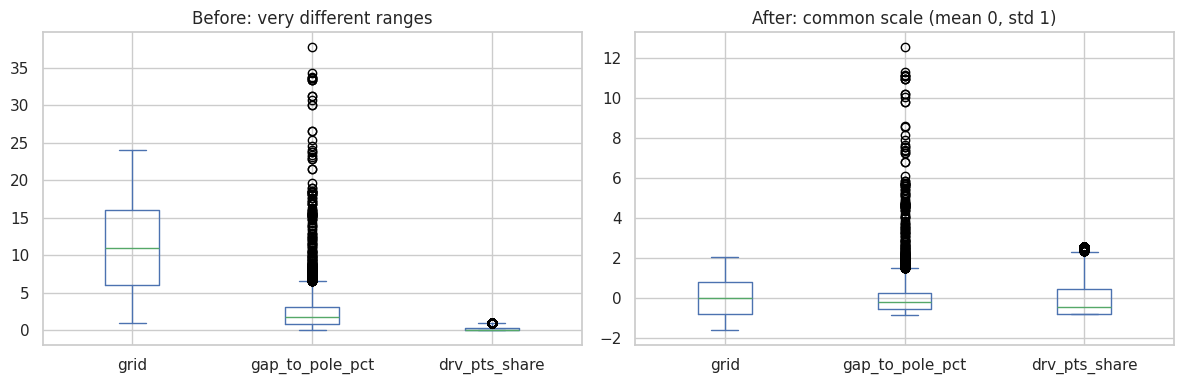

In [43]:
# ===== 10.2 Effect of preprocessing on the data (fitted on TRAIN only) =====
prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(X_tr)
after = pd.DataFrame(prep.transform(X_tr), columns=FEATURES, index=X_tr.index)
effect = pd.DataFrame({
    "missing_before": X_tr.isna().sum(), "missing_after": after.isna().sum(),
    "mean_before": X_tr.mean(), "std_before": X_tr.std(),
    "mean_after": after.mean(), "std_after": after.std(),
    "min_before": X_tr.min(), "max_before": X_tr.max(),
}).round(2)
display(effect)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
X_tr[["grid", "gap_to_pole_pct", "drv_pts_share"]].plot(kind="box", ax=axes[0], title="Before: very different ranges")
after[["grid", "gap_to_pole_pct", "drv_pts_share"]].plot(kind="box", ax=axes[1], title="After: common scale (mean 0, std 1)")
plt.tight_layout(); plt.show()

In [44]:
# ===== 10.3 Attempt 1 — BASELINE: logistic regression, default settings =====
evaluate("1. Baseline: LogReg (default)", make_pipeline(LogisticRegression(max_iter=1000)))

# ===== 10.4 Attempt 2 — Logistic regression, tuned regularisation (C) on validation =====
for C in [0.01, 0.1, 10]:   # C=1 is the default, i.e. the baseline above
    evaluate(f"2. LogReg C={C}", make_pipeline(LogisticRegression(C=C, max_iter=1000)))

1. Baseline: LogReg (default)    val PR-AUC=0.732  ROC-AUC=0.931  F1=0.694  (thr=0.31)
2. LogReg C=0.01                 val PR-AUC=0.724  ROC-AUC=0.928  F1=0.693  (thr=0.22)
2. LogReg C=0.1                  val PR-AUC=0.732  ROC-AUC=0.931  F1=0.694  (thr=0.3)
2. LogReg C=10                   val PR-AUC=0.732  ROC-AUC=0.931  F1=0.694  (thr=0.31)


In [45]:
# ===== 10.3b Naive reference (not a model): "podium if grid ≤ 3" =====
# Score = −grid (lower grid → more likely podium), so ROC-AUC / PR-AUC rank drivers by grid alone.
# Threshold −3 means "predict podium when grid ≤ 3".
REF = "0. Reference: grid ≤ 3 rule"
for s, X, y in [("train", X_tr, y_tr), ("validation", X_va, y_va)]:
    results.append({"attempt": REF, "set": s, "threshold": -3, **all_metrics(y, -X["grid"], -3)})
display(pd.DataFrame(results)[lambda d: d["attempt"] == REF].round(3))

,attempt,set,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
8,0. Reference: grid ≤ 3 rule,train,-3.0,0.908,0.626,0.646,0.647,0.646
9,0. Reference: grid ≤ 3 rule,validation,-3.0,0.909,0.639,0.692,0.692,0.692


In [46]:
# ===== 10.5 Attempt 3 — Random forest, small hyperparameter search on validation =====
for depth in [4, 8, None]:
    for leaf in [5, 20]:
        evaluate(f"3. RF depth={depth} leaf={leaf}",
                 make_pipeline(RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                                                      n_jobs=-1, random_state=SEED)))

# ===== 10.6 Attempt 4 — Gradient boosting, small hyperparameter search on validation =====
for lr in [0.03, 0.1]:
    for leaves in [8, 31]:
        evaluate(f"4. GBM lr={lr} leaves={leaves}",
                 make_pipeline(HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves,
                                                              max_iter=300, random_state=SEED)))

3. RF depth=4 leaf=5             val PR-AUC=0.727  ROC-AUC=0.932  F1=0.704  (thr=0.27)
3. RF depth=4 leaf=20            val PR-AUC=0.727  ROC-AUC=0.932  F1=0.709  (thr=0.28)
3. RF depth=8 leaf=5             val PR-AUC=0.712  ROC-AUC=0.933  F1=0.705  (thr=0.19)
3. RF depth=8 leaf=20            val PR-AUC=0.724  ROC-AUC=0.934  F1=0.703  (thr=0.35)
3. RF depth=None leaf=5          val PR-AUC=0.708  ROC-AUC=0.933  F1=0.697  (thr=0.49)
3. RF depth=None leaf=20         val PR-AUC=0.726  ROC-AUC=0.934  F1=0.704  (thr=0.27)
4. GBM lr=0.03 leaves=8          val PR-AUC=0.715  ROC-AUC=0.933  F1=0.704  (thr=0.29)
4. GBM lr=0.03 leaves=31         val PR-AUC=0.660  ROC-AUC=0.925  F1=0.712  (thr=0.25)
4. GBM lr=0.1 leaves=8           val PR-AUC=0.653  ROC-AUC=0.925  F1=0.705  (thr=0.23)
4. GBM lr=0.1 leaves=31          val PR-AUC=0.617  ROC-AUC=0.919  F1=0.690  (thr=0.27)


5. NN (32,) alpha=0.0001         val PR-AUC=0.719  ROC-AUC=0.925  F1=0.702  (thr=0.43, best epoch 55)
5. NN (32,) alpha=0.01           val PR-AUC=0.719  ROC-AUC=0.925  F1=0.705  (thr=0.44, best epoch 52)
5. NN (64, 32) alpha=0.0001      val PR-AUC=0.729  ROC-AUC=0.926  F1=0.697  (thr=0.23, best epoch 21)
5. NN (64, 32) alpha=0.01        val PR-AUC=0.736  ROC-AUC=0.926  F1=0.699  (thr=0.31, best epoch 21)


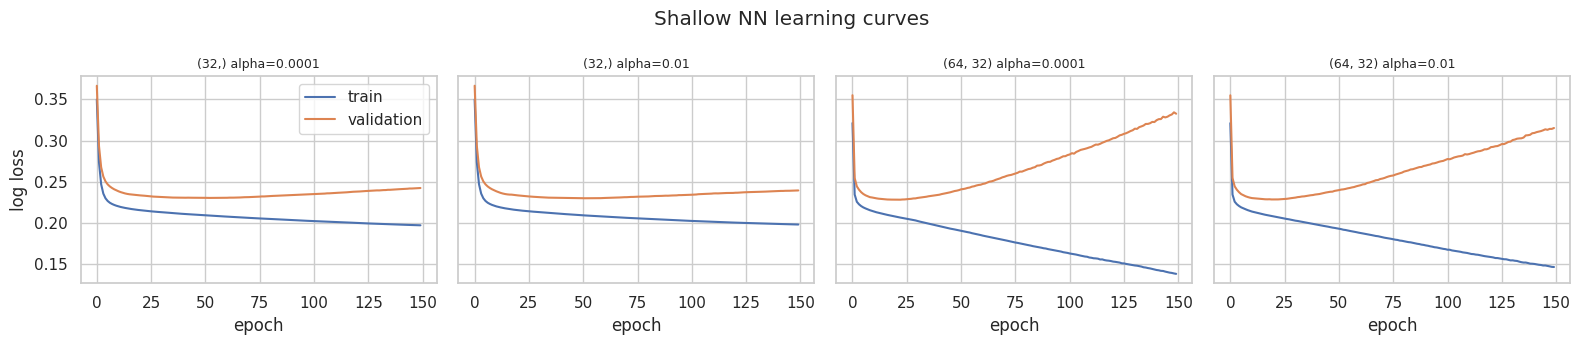

In [47]:
# ===== 10.7 Attempt 5 — Shallow neural network (1–2 hidden layers), trained epoch by epoch =====
# We train one epoch at a time and track the loss on train AND validation,
# then keep the epoch with the lowest validation loss (early stopping on validation, never on test).
prep_nn = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(X_tr)
Xtr_nn, Xva_nn = prep_nn.transform(X_tr), prep_nn.transform(X_va)

def train_mlp(hidden, alpha, epochs=150):
    mlp = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, learning_rate_init=0.001,
                        batch_size=128, random_state=SEED)
    hist, best, best_loss = [], None, np.inf
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for epoch in range(epochs):
            mlp.partial_fit(Xtr_nn, y_tr, classes=[0, 1])
            tr_loss = log_loss(y_tr, mlp.predict_proba(Xtr_nn)[:, 1])
            va_loss = log_loss(y_va, mlp.predict_proba(Xva_nn)[:, 1])
            hist.append((tr_loss, va_loss))
            if va_loss < best_loss:
                best_loss, best, best_epoch = va_loss, copy.deepcopy(mlp), epoch + 1
    return best, best_epoch, np.array(hist)

nn_runs = {}
for hidden in [(32,), (64, 32)]:
    for alpha in [1e-4, 1e-2]:
        mlp, best_epoch, hist = train_mlp(hidden, alpha)
        name = f"5. NN {hidden} alpha={alpha}"
        nn_runs[name] = hist
        pipe = Pipeline([("impute", prep_nn.named_steps["impute"]), ("scale", prep_nn.named_steps["scale"]),
                         ("model", mlp)])
        # already trained: record metrics without refitting
        p_tr, p_va = pipe.predict_proba(X_tr)[:, 1], pipe.predict_proba(X_va)[:, 1]
        thr = best_threshold(y_va, p_va)
        for s, y, p in [("train", y_tr, p_tr), ("validation", y_va, p_va)]:
            results.append({"attempt": name, "set": s, "threshold": thr, **all_metrics(y, p, thr)})
        fitted[name] = (pipe, thr)
        r = results[-1]
        print(f"{name:32s} val PR-AUC={r['PR-AUC']:.3f}  ROC-AUC={r['ROC-AUC']:.3f}  F1={r['F1']:.3f}  "
              f"(thr={thr}, best epoch {best_epoch})")

# Learning curves (training performance over time)
fig, axes = plt.subplots(1, len(nn_runs), figsize=(4 * len(nn_runs), 3.5), sharey=True)
for ax, (name, hist) in zip(axes, nn_runs.items()):
    ax.plot(hist[:, 0], label="train"); ax.plot(hist[:, 1], label="validation")
    ax.set_title(name.replace("5. NN ", ""), fontsize=9); ax.set_xlabel("epoch")
axes[0].set_ylabel("log loss"); axes[0].legend()
fig.suptitle("Shallow NN learning curves"); plt.tight_layout(); plt.show()

In [48]:
# ===== 10.8 Compare all attempts on VALIDATION and pick the best of each model family =====
res = pd.DataFrame(results)
val_res = res[res["set"] == "validation"].set_index("attempt")
display(val_res.drop(columns="set").sort_values("PR-AUC", ascending=False)
               .style.format("{:.3f}").background_gradient(subset=["PR-AUC"], cmap="Greens"))

family = val_res.index.str.extract(r"^(\d)\.", expand=False)
best_per_family = val_res.assign(family=family.values).groupby("family")["PR-AUC"].idxmax()
FINAL = ["1. Baseline: LogReg (default)"] + [best_per_family[f] for f in ["2", "3", "4", "5"]]
print("Selected on validation PR-AUC:", FINAL)

# Overfitting check: train vs validation for the selected models
gap = res[res["attempt"].isin(FINAL)].pivot(index="attempt", columns="set", values="PR-AUC").loc[FINAL]
gap["train − val"] = gap["train"] - gap["validation"]
display(gap.style.format("{:.3f}"))

,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
attempt,,,,,,
"5. NN (64, 32) alpha=0.01",0.310,0.926,0.736,0.699,0.667,0.735
2. LogReg C=0.1,0.300,0.931,0.732,0.694,0.672,0.718
1. Baseline: LogReg (default),0.310,0.931,0.732,0.694,0.672,0.718
2. LogReg C=10,0.310,0.931,0.732,0.694,0.672,0.718
"5. NN (64, 32) alpha=0.0001",0.230,0.926,0.729,0.697,0.626,0.786
3. RF depth=4 leaf=5,0.270,0.932,0.727,0.704,0.654,0.761
3. RF depth=4 leaf=20,0.280,0.932,0.727,0.709,0.664,0.761
3. RF depth=None leaf=20,0.270,0.934,0.726,0.704,0.662,0.752
2. LogReg C=0.01,0.220,0.928,0.724,0.693,0.642,0.752


Selected on validation PR-AUC: ['1. Baseline: LogReg (default)', '2. LogReg C=0.1', '3. RF depth=4 leaf=5', '4. GBM lr=0.03 leaves=8', '5. NN (64, 32) alpha=0.01']


set,train,validation,train − val
attempt,,,
1. Baseline: LogReg (default),0.691,0.732,-0.040
2. LogReg C=0.1,0.691,0.732,-0.041
3. RF depth=4 leaf=5,0.727,0.727,-0.000
4. GBM lr=0.03 leaves=8,0.789,0.715,0.074
"5. NN (64, 32) alpha=0.01",0.717,0.736,-0.018


**Observation (10.8, validation):**
- **The models are very close:** the selected models range from 0.715 (gradient boosting) to 0.736 (neural network) validation PR-AUC.
  Logistic regression scores 0.732 with C = 0.1, 1 (default) or 10; only C = 0.01 is lower (0.724), so regularisation barely matters here.
- **Every model clearly beats the naive "grid ≤ 3" rule** (0.639), by about 0.08–0.10 PR-AUC: the other features add real information beyond the starting position.
- **Overfitting check:** gradient boosting fits training much better than validation (0.789 vs 0.715), so it memorises training patterns.
  The random forest (depth 4) shows no gap, and logistic regression and the network score *higher* on validation than on training.
- **Why validation can beat training:** 2020–2021 were dominated by very few drivers and teams, which makes podiums easier to predict than the average
  2003–2019 season. It is a property of those seasons, not a sign of leakage (the split checks and leakage checks passed).
- **Why the top score here is not the final model:** the network ranks first on validation (0.736 vs 0.732 for logistic regression),
  but every model in this table was trained **once, with a single seed** (`SEED = 42`). A lead of 0.004 from one run cannot tell us
  whether the network is really better or whether this seed happened to give it a good start.
  The seed-stability check in **11.4** answers this: retrained with 5 different seeds, the network scores **0.732 ± 0.007**
  (range 0.719–0.737), i.e. its score moves by up to 0.018 from the seed alone, more than four times its lead here.
  On average it is tied with logistic regression (0.732, which has no randomness).
  → The two models are **effectively tied on accuracy**, so the final choice is made in 11.4 on the remaining criteria:
  **logistic regression (C = 0.1)** gives the same result on every run and is directly interpretable.

### 10.9 Training-years experiment (decision 1)
Same best statistical model and same features; only the training years change (2003–2019 vs 1950–2019), scored on the same 2020–2021 validation races.
**If `all_years` wins, set `TABLE = "all_years"` in 10.1 and re-run Section 10 before the final test cell.**

In [49]:
# ===== 10.9 Training-years experiment (decision 1): same best model, two training sets =====
# use the best STATISTICAL model (the NN is trained epoch-by-epoch with early stopping, so a plain .fit() would differ)
best_name = val_res.loc[FINAL[:-1], "PR-AUC"].idxmax()
best_pipe = fitted[best_name][0]
print(f"Best statistical model on validation: {best_name}")

year_rows = []
for table_name, (tr, va, _) in splits.items():
    pipe = copy.deepcopy(best_pipe)
    pipe.fit(tr[FEATURES], tr["podium"])
    p = pipe.predict_proba(va[FEATURES])[:, 1]
    year_rows.append({"training data": table_name, "train rows": len(tr),
                      **all_metrics(va["podium"], p, best_threshold(va["podium"], p))})
display(pd.DataFrame(year_rows).set_index("training data").style.format("{:.3f}", subset=["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]))

Best statistical model on validation: 2. LogReg C=0.1


,train rows,ROC-AUC,PR-AUC,F1,Precision,Recall
training data,,,,,,
from_2003,6821,0.931,0.732,0.694,0.672,0.718
all_years,22589,0.929,0.723,0.701,0.650,0.761


**Observation (10.9, decision 1):** training on **2003–2019 scores higher** (PR-AUC 0.732) than training on 1950–2019 (0.723), even though the
all-years table has 3.3× more training rows. Older seasons (larger fields, unreliable cars, no qualifying data) teach patterns that no longer hold,
so more data is not better here. **Decision 1: train from 2003** (`TABLE = "from_2003"`).

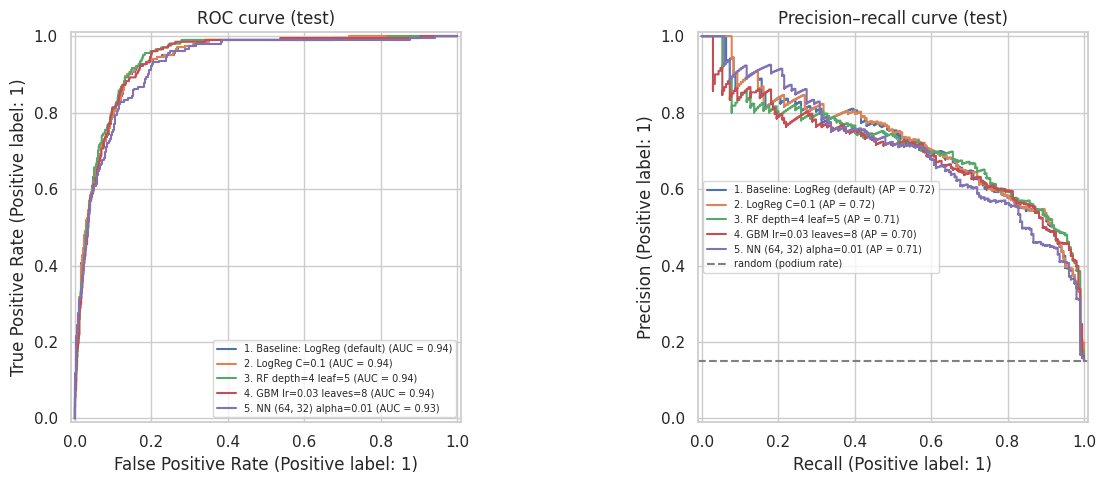

In [50]:
# ===== 10.10 FINAL: unseen test set (run once, after every choice above is fixed) =====
for name in FINAL:
    pipe, thr = fitted[name]
    p_te = pipe.predict_proba(X_te)[:, 1]
    results.append({"attempt": name, "set": "test", "threshold": thr, **all_metrics(y_te, p_te, thr)})

results.append({"attempt": REF, "set": "test", "threshold": -3, **all_metrics(y_te, -X_te["grid"], -3)})

res = pd.DataFrame(results)
SHOW = [REF] + FINAL
comparison = (res[res["attempt"].isin(SHOW) & res["set"].isin(["train", "validation", "test"])]
                .set_index(["attempt", "set"])[["threshold", "ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]]
                .loc[SHOW])
display(comparison.style.format("{:.3f}"))

# ROC and precision-recall curves on the test set
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in FINAL:
    p_te = fitted[name][0].predict_proba(X_te)[:, 1]
    RocCurveDisplay.from_predictions(y_te, p_te, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_te, p_te, name=name, ax=axes[1])
axes[1].axhline(y_te.mean(), ls="--", c="grey", label="random (podium rate)")
axes[0].set_title("ROC curve (test)"); axes[1].set_title("Precision–recall curve (test)")
for ax in axes: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Observation (10.10, unseen test 2022–2024):**
| Model | Validation PR-AUC | Test PR-AUC | Test F1 |
|---|---|---|---|
| Reference: grid ≤ 3 | 0.639 | 0.647 | 0.649 |
| Logistic regression (baseline) | 0.732 | 0.720 | 0.665 |
| **Logistic regression, C = 0.1 (final)** | **0.732** | **0.723** | **0.670** |
| Random forest | 0.727 | 0.713 | 0.682 |
| Gradient boosting | 0.715 | 0.700 | 0.672 |
| Shallow neural network | 0.736 | 0.706 | 0.648 |

- **The models generalise to the new era:** test PR-AUC drops only ~0.01 from validation for logistic regression, even though 2022 brought a major
  regulation change. All models stay well above the reference rule (+0.05 to +0.08 PR-AUC) and reach ROC-AUC 0.93–0.94.
- **The network drops the most** (0.736 → 0.706), consistent with its validation lead being seed luck (11.4).
- **Final model: logistic regression (C = 0.1)**, chosen on validation in 11.4 (tied with the network on accuracy, but no randomness and directly interpretable). Its test PR-AUC (0.723) confirms the choice. At the validation-chosen
  threshold (0.30) it finds **about 3 of every 4 podiums** (recall 0.755), and **6 of every 10** predicted podiums are correct (precision 0.60).
- The thresholds were chosen on validation and not changed after seeing the test set.

## 11. Experiments
Four experiments, each changing one thing: feature-group ablation (11.1), preprocessing order (11.2), our data decisions (11.3) and seed stability (11.4).

### 11.0 How the experiments are run
Every experiment changes **one thing** and keeps everything else fixed: the same model, the same training rows (2003–2019),
and the same scoring on **validation (2020–2021)**.Test **labels** are never used in this section; only the leaky variants in 11.2 deliberately include test *features* when fitting the scaler/imputer, to show what that leak would do.
The model is the best statistical model chosen in 10.9. Ablations are also repeated with the best random forest,
because tree models and linear models react differently to correlated features.

In [51]:
# ===== 11.0 Shared helper: refit a fresh copy of a model on chosen columns, score on VALIDATION only =====
from sklearn.base import clone

EXP_MODEL_NAME = best_name                              # best statistical model (10.9)
EXP_MODEL      = fitted[EXP_MODEL_NAME][0]
RF_NAME        = best_per_family["3"]                   # best random forest (10.8)
RF_MODEL       = fitted[RF_NAME][0]
print("Main experiment model:", EXP_MODEL_NAME, "| tree model:", RF_NAME)

def val_score(cols, model=None, Xtr=None, Xva=None):
    """Fit a fresh copy of `model` on the training rows (only `cols`), return validation metrics."""
    Xtr = X_tr if Xtr is None else Xtr
    Xva = X_va if Xva is None else Xva
    pipe = clone(EXP_MODEL if model is None else model)          # clone = same settings, not yet trained
    pipe.fit(Xtr[cols], y_tr)
    p = pipe.predict_proba(Xva[cols])[:, 1]
    thr = best_threshold(y_va, p)
    return {"PR-AUC": average_precision_score(y_va, p), "ROC-AUC": roc_auc_score(y_va, p),
            "F1": f1_score(y_va, p >= thr, zero_division=0)}

Main experiment model: 2. LogReg C=0.1 | tree model: 3. RF depth=4 leaf=5


### 11.1 Feature-group ablation
Remove **one feature group at a time** and retrain. A big drop in validation PR-AUC means the group carries information
the others do not. A drop near zero means the group is redundant (the other groups already cover it).
The "only this group" rows show how much each group can do on its own.

In [ ]:
# ===== 11.1 Feature-group ablation =====
RARE_FLAGS = ["pit_lane_start", "has_quali", "no_quali_time"]          # near-constant in 2003+ rows

def ablation(model):
    rows = {"all features": val_score(FEATURES, model)["PR-AUC"]}
    for g, cols in FEATURE_GROUPS.items():
        rows[f"without {g}"] = val_score([c for c in FEATURES if c not in cols], model)["PR-AUC"]
    rows["without rare flags"] = val_score([c for c in FEATURES if c not in RARE_FLAGS], model)["PR-AUC"]
    for g, cols in FEATURE_GROUPS.items():
        rows[f"only {g}"] = val_score(cols, model)["PR-AUC"]
    return pd.Series(rows)

abl = pd.DataFrame({"LogReg PR-AUC": ablation(EXP_MODEL), "RF PR-AUC": ablation(RF_MODEL)})
for m in ["LogReg", "RF"]:
    abl[f"{m} Δ vs all"] = abl[f"{m} PR-AUC"] - abl.loc["all features", f"{m} PR-AUC"]
display(abl.style.format("{:+.3f}", subset=["LogReg Δ vs all", "RF Δ vs all"])
               .format("{:.3f}", subset=["LogReg PR-AUC", "RF PR-AUC"]))

drop = abl.loc[[i for i in abl.index if i.startswith("without")], ["LogReg Δ vs all", "RF Δ vs all"]]
drop.plot(kind="barh", figsize=(9, 4), title="Change in validation PR-AUC when a group is removed")
plt.axvline(0, c="grey", lw=1); plt.xlabel("Δ PR-AUC (negative = the group helped)"); plt.tight_layout(); plt.show()

**Observation (ablation):**
- **No single group is essential.** Removing any one group costs at most 0.013 (LogReg) / 0.019 (RF) PR-AUC, because the groups overlap:
  grid, qualifying, form and standings all partly measure car performance.
- **Qualifying is the most useful group** (largest drop when removed, and the best group on its own: 0.67–0.68).
  It adds information beyond grid: penalties, and the gap to pole.
- **Standings are second** (−0.011 / −0.013). **Constructor form is redundant** once standings are present (removal costs ~0).
- **No group alone comes close to all features** (best alone 0.68 vs 0.73), so combining them is what makes the model work.
- **Rare flags** (`pit_lane_start`, `has_quali`, `no_quali_time`) add almost nothing (≤ 0.003); they are kept because they are cheap and matter for the all-years option.
- Caveat: validation has ~117 podiums, so differences below ~0.01 are within noise (see the seed spread in 11.4).

### 11.2 Preprocessing-order experiments
The pipeline learns the imputation medians and the scaling mean/std **from the training rows only**.
These experiments show what changes if that order is broken:
- **A. Correct:** imputer and scaler fitted on train only (what the pipeline does).
- **B. Scaler fitted on all data:** mean/std computed on train + validation + test before splitting (leaky).
- **C. Imputer fitted on all data:** "impute before the split", medians from train + validation + test (leaky).
- **D. Both leaky.**
- **E. No scaling:** imputation only, to show whether scaling matters for this model.

All five use the same logistic-regression settings and are scored on validation.

In [ ]:
# ===== 11.2 Preprocessing-order experiments (same model, only the preprocessing changes) =====
X_all = pd.concat([X_tr, X_va, X_te])                   # what a careless "preprocess first, split later" sees
lr_model = clone(EXP_MODEL.named_steps["model"])

def run_prep(imp_fit_on, scl_fit_on=None):
    imp = SimpleImputer(strategy="median").fit(imp_fit_on)
    tr, va = imp.transform(X_tr), imp.transform(X_va)
    if scl_fit_on is not None:
        scl = StandardScaler().fit(imp.transform(scl_fit_on))
        tr, va = scl.transform(tr), scl.transform(va)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                   # unscaled LogReg may warn about convergence
        m = clone(lr_model).fit(tr, y_tr)
    p = m.predict_proba(va)[:, 1]
    thr = best_threshold(y_va, p)
    return {"PR-AUC": average_precision_score(y_va, p), "ROC-AUC": roc_auc_score(y_va, p),
            "F1": f1_score(y_va, p >= thr, zero_division=0)}

prep_exp = pd.DataFrame({
    "A. correct (train only)":       run_prep(X_tr,  X_tr),
    "B. scaler fit on all data":     run_prep(X_tr,  X_all),
    "C. imputer fit on all data":    run_prep(X_all, X_tr),
    "D. both fit on all data":       run_prep(X_all, X_all),
    "E. no scaling":                 run_prep(X_tr,  None),
}).T
prep_exp["Δ PR-AUC vs A"] = prep_exp["PR-AUC"] - prep_exp.loc["A. correct (train only)", "PR-AUC"]
display(prep_exp.style.format("{:.4f}"))

# Why the leak is small here: how much do the statistics move when validation + test are included?
stats = pd.DataFrame({"train mean": X_tr.mean(), "all-data mean": X_all.mean(),
                      "train median": X_tr.median(), "all-data median": X_all.median()})
stats["mean shift (in train std)"] = (stats["all-data mean"] - stats["train mean"]) / X_tr.std()
display(stats.sort_values("mean shift (in train std)", key=abs, ascending=False).head(6).round(3))

**Observation (preprocessing order):**
- Fitting the scaler and/or the imputer on all data (B–D) changes validation PR-AUC by **0.0001**: practically nothing.
- The reason is visible in the second table: the training statistics are very close to the all-data statistics
  (the largest mean shift is `field_size`, 0.21 training standard deviations). There is little to leak.
- **No scaling (E)** lowers PR-AUC by 0.004 for logistic regression.
→ The leak is harmless **on this dataset**, but the correct order (fit on train only, inside the pipeline) is kept because it is the only one
that is valid in general: with a larger shift between train and test (e.g. a new era), a leaky scaler or imputer would make the scores optimistic.

### 11.3 Our data decisions: do they change the result?
Two cleaning/feature decisions from Section 8 are tested against the simpler alternative:
- **Team form by lineage vs by `constructorId`** (8.1c).
- **Same-race qualifying fills vs median imputation** (8.1b): the filled values are put back to missing, the `no_quali_time` flag is removed,
  and the pipeline's training median fills them instead.

In [ ]:
# ===== 11.3 Data-decision experiments =====
TEAM = FEATURE_GROUPS["constructor_form"]

def with_byid(X):
    """Same rows, but team form computed by raw constructorId instead of lineage."""
    X = X.copy()
    for c in TEAM:
        X[c] = df.loc[X.index, c + "_byid"].values
    return X

def undo_quali_fills(X):
    """Put the 8.1b fills back to missing, so the pipeline's median imputer handles them."""
    X = X.copy()
    gap_was_missing = (X["no_quali_time"] == 1) | (X["has_quali"] == 0)
    X.loc[gap_was_missing, "gap_to_pole_pct"] = np.nan
    X.loc[X["has_quali"] == 0, ["quali_pos", "grid_minus_quali"]] = np.nan
    return X

no_flag = [c for c in FEATURES if c != "no_quali_time"]
changed_tr = int((with_byid(X_tr)[TEAM].fillna(-1) != X_tr[TEAM].fillna(-1)).any(axis=1).sum())
filled_tr  = int(((X_tr["no_quali_time"] == 1) | (X_tr["has_quali"] == 0)).sum())
print(f"Training rows whose team form differs (lineage vs ID): {changed_tr}")
print(f"Training rows with a filled qualifying value:          {filled_tr}")

dec = {}
for label, model in [("LogReg", EXP_MODEL), ("RF", RF_MODEL)]:
    dec[label] = {
        "our version (lineage + same-race fills)": val_score(FEATURES, model)["PR-AUC"],
        "team form by constructorId":             val_score(FEATURES, model, with_byid(X_tr), with_byid(X_va))["PR-AUC"],
        "qualifying gaps → training median":      val_score(no_flag, model, undo_quali_fills(X_tr), undo_quali_fills(X_va))["PR-AUC"],
    }
dec = pd.DataFrame(dec)
for m in ["LogReg", "RF"]:
    dec[f"{m} Δ"] = dec[m] - dec.loc["our version (lineage + same-race fills)", m]
display(dec.style.format("{:.4f}", subset=["LogReg", "RF"]).format("{:+.4f}", subset=["LogReg Δ", "RF Δ"]))

**Observation (data decisions):**
- **Team lineage** changes team form for 308 training rows, but validation PR-AUC moves by only −0.001 (LogReg) / +0.001 (RF): no measurable effect.
- **Same-race qualifying fills** vs the training median (124 training rows): our fills score slightly higher (+0.003 LogReg, +0.001 RF).
→ Both fixes are kept as **correctness** fixes (they stop the model from seeing false information, e.g. Mercedes 2010 using 1955 form),
not because they raise the score. Few rows are affected, and those are mostly non-podium drivers, so the score barely moves.

### 11.4 Seed stability: are the differences between models real?
The random forest and the neural network depend on a random seed (which rows each tree sees; the network's starting weights).
Each was trained once with `SEED = 42`. Here the selected settings are retrained with 5 different seeds.
If the spread across seeds is as large as the gap between models, the ranking in 10.8 is down to luck.
Logistic regression has no randomness, so it gives one value.

In [ ]:
# ===== 11.4 Seed stability (validation PR-AUC) =====
import ast
NN_NAME = best_per_family["5"]
nn_hidden = ast.literal_eval(NN_NAME.split("NN ")[1].split(" alpha")[0])
nn_alpha  = float(NN_NAME.split("alpha=")[1])

def nn_val_pr_auc(seed, epochs=150):
    """Same training as 10.7 (epoch by epoch, keep the epoch with the lowest validation loss), different seed."""
    mlp = MLPClassifier(hidden_layer_sizes=nn_hidden, alpha=nn_alpha, learning_rate_init=0.001,
                        batch_size=128, random_state=seed)
    best_loss, best_p = np.inf, None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for _ in range(epochs):
            mlp.partial_fit(Xtr_nn, y_tr, classes=[0, 1])
            p = mlp.predict_proba(Xva_nn)[:, 1]
            loss = log_loss(y_va, p)
            if loss < best_loss:
                best_loss, best_p = loss, p
    return average_precision_score(y_va, best_p)

SEEDS = [0, 1, 2, 3, 4]
seed_rows = []
for s in SEEDS:
    rf = clone(RF_MODEL).set_params(model__random_state=s).fit(X_tr, y_tr)
    seed_rows.append({"seed": s,
                      "RF": average_precision_score(y_va, rf.predict_proba(X_va)[:, 1]),
                      "NN": nn_val_pr_auc(s)})
seeds = pd.DataFrame(seed_rows).set_index("seed")
lr_val = val_res.loc[EXP_MODEL_NAME, "PR-AUC"]
summary = pd.DataFrame({"mean": seeds.mean(), "std": seeds.std(), "min": seeds.min(), "max": seeds.max()})
summary.loc["LogReg (no randomness)"] = [lr_val, 0, lr_val, lr_val]
print(f"RF: {RF_NAME} | NN: {NN_NAME}")
display(seeds.round(4))
display(summary.round(4))

**Observation (seed stability):**
- Random forest: 0.725 ± 0.003 across 5 seeds (range 0.722–0.728). Stable.
- Neural network: 0.732 ± 0.007 (range 0.719–0.737). The spread is about as large as the gaps between models in 10.8.
- Logistic regression: 0.732, with no randomness.
- The network's average equals logistic regression, so its lead in 10.8 (0.736) came from a lucky seed.
→ The models are effectively tied. **Logistic regression is the preferred final model**: same accuracy, no randomness, and directly interpretable.

## 12. Explainability (XAI)

We explain the **final model**, logistic regression (chosen in 11.4: same accuracy as the other models, no randomness, directly interpretable).
The random forest is shown next to it in the permutation importance for comparison.

| Method | Scope | Question it answers |
|---|---|---|
| **Permutation importance** | Global | How much does validation PR-AUC drop if one feature's values are shuffled (its information destroyed)? |
| **SHAP** | Global + local | How much does each feature push each prediction up or down from the average prediction? |
| **LIME** | Local | Around one specific driver-race, which features drive this single prediction? |

> **Importance is not causation.** A feature being important only means the **model relies on it to make predictions**.
> It does not prove that the feature *causes* podium finishes. For example, `con_pts_share` is important because teams with many points
> usually have fast cars; the points themselves do not make the car faster. Changing a feature's value in the real world would not
> necessarily change the outcome the way the model's weights suggest.

In [ ]:
# ===== 12.1 Global: permutation importance (on VALIDATION, scored with PR-AUC) =====
from sklearn.inspection import permutation_importance

# Final model = logistic regression (11.4: tied with the others on accuracy, but no randomness and interpretable)
FINAL_NAME = (EXP_MODEL_NAME if "LogReg" in EXP_MODEL_NAME
              else val_res.loc[[n for n in FINAL if "LogReg" in n], "PR-AUC"].idxmax())
FINAL_PIPE, FINAL_THR = fitted[FINAL_NAME]
print("Final model:", FINAL_NAME, "| threshold:", FINAL_THR)

def perm_imp(pipe):
    r = permutation_importance(pipe, X_va, y_va, scoring="average_precision",
                               n_repeats=10, random_state=SEED, n_jobs=-1)
    return pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std}, index=FEATURES)

pi_lr = perm_imp(FINAL_PIPE)
pi_rf = perm_imp(RF_MODEL)
pi = pd.DataFrame({"LogReg (final)": pi_lr["mean"], "LogReg std": pi_lr["std"],
                   "RF": pi_rf["mean"], "RF std": pi_rf["std"]}).sort_values("LogReg (final)", ascending=False)
display(pi.style.format("{:.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
order = pi.index[::-1]
for ax, col, err, title in [(axes[0], "LogReg (final)", "LogReg std", "Logistic regression (final)"),
                            (axes[1], "RF", "RF std", "Random forest (comparison)")]:
    ax.barh(order, pi.loc[order, col], xerr=pi.loc[order, err])
    ax.axvline(0, c="grey", lw=1); ax.set_title(title); ax.set_xlabel("drop in validation PR-AUC when shuffled")
fig.suptitle("Permutation importance"); plt.tight_layout(); plt.show()

print("Top 5 (LogReg):", list(pi.index[:5]))
print("Top 5 (RF):    ", list(pi["RF"].sort_values(ascending=False).index[:5]))

**How to read it:** each bar is how much validation PR-AUC drops when that one feature is shuffled. Bigger = the model relies on it more.
A value near 0 (or slightly negative) means the model barely uses it, *given the other features*.

**Interpretation:**
- **Final model (logistic regression):** the most important features are `quali_pos` (−0.038 PR-AUC when shuffled), `grid_rel` (0.037),
  `team_best_finish_last5` (0.035), `drv_podium_rate_last5` (0.034) and `grid` (0.032): **where the driver starts, how he qualified, and how well he and his team did recently.**
- **Random forest:** relies mostly on starting position and qualifying (`grid_rel` 0.030, `quali_pos` 0.027, `grid` 0.027, `gap_to_pole_pct` 0.014)
  and much less on form features. Both models agree that **qualifying and grid** are the core signal, which matches the ablation (11.1),
  where qualifying was the most useful group.
- **Near zero for both:** `field_size`, `team_mech_rate_last10`, `has_quali`, `con_wins_before`.
- **Uncertainty is large:** standard deviations are about half the means (e.g. 0.038 ± 0.019), because validation contains only ~117 podiums.
  The order of the top five should not be over-read.
- **Why this can differ from the ablation:** permutation importance shuffles a feature **while keeping the trained model fixed**, so it shows what this
  model relies on. The ablation **retrains** without the group, and the model can then lean on overlapping features instead. This is why
  `team_best_finish_last5` matters here but removing the whole constructor-form group cost almost nothing in 11.1: standings carry similar information.
- **Correlated features share credit:** grid, `grid_rel`, `quali_pos` and `gap_to_pole_pct` overlap, so shuffling one of them hurts less than its true usefulness.

In [ ]:
# ===== 12.2 Global: SHAP (logistic regression → exact linear SHAP values) =====
import shap

prep_final = FINAL_PIPE[:-1]                            # imputer + scaler, fitted on train
lr_final   = FINAL_PIPE.named_steps["model"]
Xtr_t = pd.DataFrame(prep_final.transform(X_tr), columns=FEATURES, index=X_tr.index)
Xva_t = pd.DataFrame(prep_final.transform(X_va), columns=FEATURES, index=X_va.index)

explainer = shap.LinearExplainer(lr_final, Xtr_t)       # background = training rows
sv = explainer(Xva_t)                                   # SHAP values in log-odds, one per (row, feature)

# Show feature values on their ORIGINAL scale (after imputation) instead of standardised units
X_va_imputed = pd.DataFrame(FINAL_PIPE.named_steps["impute"].transform(X_va), columns=FEATURES, index=X_va.index)
sv_disp = shap.Explanation(values=sv.values, base_values=sv.base_values,
                           data=X_va_imputed.values, feature_names=FEATURES)

plt.figure()                                            # fresh figure for the SHAP plot
shap.plots.beeswarm(sv_disp, max_display=20, show=False)
plt.title("SHAP summary (validation 2020–2021): effect of each feature on the log-odds of a podium")
plt.tight_layout(); plt.show()

mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
mean_abs[::-1].plot(kind="barh", figsize=(8, 6), title="Mean |SHAP value| per feature (validation)")
plt.xlabel("average impact on the log-odds of a podium"); plt.tight_layout(); plt.show()
print("Top 5 by mean |SHAP|:", list(mean_abs.index[:5]))

**How to read the beeswarm:** each dot is one driver-race in validation. Position left/right = how much that feature pushed the prediction
**down/up** (in log-odds); colour = the feature's value (red high, blue low).

**Interpretation:**
- **Largest average effects:** `team_best_finish_last5`, `grid_rel`, `quali_pos`, `grid` and `drv_podium_rate_last5`, the same features that lead
  the permutation importance.
- **Directions match the EDA (8.8):** a low (good) team best finish, grid and qualifying position push the prediction **up** (blue dots on the right);
  a high recent podium rate, many wins so far and a high constructor points share push it up; a pit-lane start pushes it strongly **down**.
- **Counter-intuitive signs come from overlapping features:** a high `team_podiums_last5` pushes the prediction *down*, although its correlation with
  podiums is +0.51 (8.8). It carries almost the same information as `team_best_finish_last5`, so the linear model gives the latter a large positive effect
  and uses the former as a small correction. **Together** their effect is positive; neither weight should be read on its own.
- **`no_quali_time` has one large positive dot (+2.8).** In training, drivers without a qualifying time were often fast drivers who crashed or failed in
  qualifying, so the "slowest gap" fill overstates how slow they are and the flag corrects for it. This rests on very few rows (124 training rows with a filled
  qualifying value) and should not be over-interpreted.
- `gap_to_pole_pct` has a small effect in this model because `quali_pos` already carries most of the same information.
- **These are the model's reasons, not causes:** SHAP describes which inputs the model relies on, not what makes a driver reach the podium.

In [ ]:
# ===== 12.3 Local: explain ONE prediction with SHAP (waterfall) and LIME =====
from lime.lime_tabular import LimeTabularExplainer

p_va = FINAL_PIPE.predict_proba(X_va)[:, 1]
names = (val_df[["raceId", "driverId", "year", "grid"]]
         .merge(clean["drivers"][["driverId", "forename", "surname"]], on="driverId", how="left")
         .merge(clean["races"][["raceId", "name"]], on="raceId", how="left"))
names.index = val_df.index
names["p_podium"], names["actual_podium"] = p_va, y_va.values

# An interesting case: the driver starting OUTSIDE the top 3 whom the model rates most likely to reach the podium
case = names[names["grid"] > 3].sort_values("p_podium", ascending=False).index[0]
pos  = X_va.index.get_loc(case)
info = names.loc[case]
print(f"Case: {info['forename']} {info['surname']}, {info['name']} {info['year']}, grid {int(info['grid'])}")
print(f"Predicted podium probability: {info['p_podium']:.2f} (threshold {FINAL_THR}) | actual podium: {bool(info['actual_podium'])}")
display(X_va.loc[[case]].T.rename(columns={case: "feature value"}))

# SHAP waterfall: from the average prediction (base value) to this driver's prediction
plt.figure()                                            # fresh figure for the SHAP plot
shap.plots.waterfall(sv_disp[pos], max_display=12, show=False)
plt.title("SHAP waterfall for this driver-race (log-odds)"); plt.tight_layout(); plt.show()

# LIME: fits a small, simple model around this one row and reports which features drive it locally
X_tr_imputed = FINAL_PIPE.named_steps["impute"].transform(X_tr)
lime_exp = LimeTabularExplainer(X_tr_imputed, feature_names=FEATURES, class_names=["no podium", "podium"],
                                mode="classification", discretize_continuous=True, random_state=SEED)
predict_fn = lambda a: FINAL_PIPE.predict_proba(pd.DataFrame(a, columns=FEATURES))
exp = lime_exp.explain_instance(X_va_imputed.loc[case].values, predict_fn, num_features=10, num_samples=5000)
fig = exp.as_pyplot_figure(); plt.title("LIME explanation for the same driver-race (class: podium)")
plt.tight_layout(); plt.show()
display(pd.DataFrame(exp.as_list(), columns=["condition", "weight toward podium"]))
print(f"LIME's local model predicts {exp.local_pred[0]:.2f} vs the real model {info['p_podium']:.2f} (closer = more faithful)")

**The case: Max Verstappen, Qatar Grand Prix 2021.** He **qualified 2nd** but received a **5-place grid penalty** and **started 7th**
(`grid_minus_quali = 5`). The model gave him **0.72** (threshold 0.30), so it predicted a podium, and he **finished on the podium**: a correct prediction
that the "grid ≤ 3" rule would have missed.

**SHAP waterfall (exact for a linear model):** starting from the average log-odds (−3.49), the prediction is pushed up mainly by his recent podium rate
(5 of the last 5 races, **+1.09**), his team's recent best finishes (average 1.6, **+0.94**), qualifying 2nd (**+0.79**) and 9 wins so far (**+0.62**).
His grid position of 7 still helps a little (**+0.35**, better than the average starter) and the penalty signal `grid_minus_quali = 5` adds **+0.26**:
the model "knows" a fast car is starting further back than its pace. `team_podiums_last5` pushes down (−0.40) for the overlap reason explained in 12.2.

**LIME:** its local model predicts **0.19** while the real model says **0.72**, so for this row **LIME is not a faithful explanation**.
Its largest weight goes to `no_quali_time <= 0` (−0.30), a binary flag that is 0 for almost every row: LIME creates thousands of random variations of the row,
many of them unrealistic (e.g. no qualifying time combined with a qualifying position of 2), and fits a simple model to them.
Its remaining conditions do agree with SHAP: good team finishes, qualifying in the top 6, a recent podium rate above 0.2 and a high constructor points
share push toward a podium, while not starting on the front row pushes away.

**Conclusion:** for this logistic-regression model the **SHAP explanation is the reliable one** (it is exact and adds up to the real prediction);
LIME is an approximation whose quality depends on random sampling and on how the features are perturbed. A possible improvement would be to declare the
binary flags as categorical in LIME so that they are perturbed realistically.

## 13. Inference function

`predict_podium(record)` takes **one driver-race record** (a dictionary of pre-race feature values) and returns the podium probability
from the final model, the yes/no decision at the validation-chosen threshold, and the list of fields that were missing.
- **Missing fields** (absent, `None` or `NaN`) are filled by the pipeline's **training medians**, the same way as during training.
- **Post-race fields are rejected** (e.g. `points`, `laps`, `positionOrder`), so the function cannot be fed leaked information by mistake.
- `record_from_table(raceId, driverId)` builds a record from the modeling table, which is how the demos below get realistic inputs.

In [ ]:
# ===== 13. Inference function =====
def predict_podium(record, pipe=None, threshold=None):
    """Predict the podium probability for ONE driver in ONE race from pre-race features only."""
    pipe = FINAL_PIPE if pipe is None else pipe
    threshold = FINAL_THR if threshold is None else threshold
    leaked = set(record) & set(POST_RACE)
    if leaked:
        raise ValueError(f"Post-race fields are not allowed as inputs: {sorted(leaked)}")
    unknown = set(record) - set(FEATURES)
    row = pd.DataFrame([{f: record.get(f, np.nan) for f in FEATURES}]).astype(float)
    missing = [f for f in FEATURES if pd.isna(row.at[0, f])]
    p = float(pipe.predict_proba(row)[:, 1][0])
    return {"podium_probability": round(p, 3), "predicted_podium": bool(p >= threshold),
            "threshold": threshold, "missing_fields_filled": missing, "ignored_fields": sorted(unknown)}

def record_from_table(race_id, driver_id):
    """Build an input record (pre-race features only) for one driver-race from the modeling table."""
    row = model_df[(model_df["raceId"] == race_id) & (model_df["driverId"] == driver_id)]
    assert len(row) == 1, "driver-race not found"
    return row[FEATURES].iloc[0].to_dict()

# --- Demo 1: a COMPLETE record from the unseen test set (the pole sitter of the last test race) ---
last_race = test_df["raceId"].iloc[np.argmax(test_df["date"].values)]
pole = test_df[test_df["raceId"] == last_race].sort_values("grid").iloc[0]
rec_full = record_from_table(pole["raceId"], pole["driverId"])
who = clean["drivers"].set_index("driverId").loc[pole["driverId"]]
race_name = clean["races"].set_index("raceId").loc[pole["raceId"], "name"]
print(f"Demo 1 — complete record: {who['forename']} {who['surname']}, {race_name} {int(pole['year'])}, grid {int(pole['grid'])}")
print(predict_podium(rec_full), "| actual podium:", bool(pole["podium"]))

# --- Demo 2: a PARTIALLY MISSING record (same driver, but no qualifying data and no recent form known) ---
rec_partial = {k: v for k, v in rec_full.items()
               if k not in FEATURE_GROUPS["qualifying"] + FEATURE_GROUPS["driver_form"]}
print(f"\nDemo 2 — partial record ({len(rec_partial)} of {len(FEATURES)} fields given):")
print(predict_podium(rec_partial))

# --- Demo 3: the leakage guard ---
try:
    predict_podium({**rec_full, "points": 25})
except ValueError as e:
    print("\nDemo 3 — leakage guard:", e)

# --- Bonus: the whole field of that race, ranked by predicted probability ---
field = test_df[test_df["raceId"] == last_race].copy()
field["p_podium"] = [predict_podium(record_from_table(r, d))["podium_probability"]
                     for r, d in zip(field["raceId"], field["driverId"])]
field = field.merge(clean["drivers"][["driverId", "surname"]], on="driverId")
display(field.sort_values("p_podium", ascending=False)[["surname", "grid", "p_podium", "podium"]].head(8)
             .rename(columns={"podium": "actual podium"}).reset_index(drop=True))

**Reading the demos:**
- **Complete record (Lando Norris, Abu Dhabi 2024, pole position):** probability **0.73**, above the 0.30 threshold → podium predicted, and he did finish on the podium.
- **Partial record** (same driver, qualifying and recent-form fields removed): the probability falls to **0.42**. The missing values are filled with training medians,
  i.e. "an average qualifier with average form", so the prediction moves toward the middle and is driven mainly by grid and standings. It is still above the
  threshold, because pole position and strong standings remain. This shows a limitation: the function cannot know *why* a value is missing, so "unknown" is treated as "average".
- **Leakage guard:** a record containing `points` is rejected.
- **Whole race:** the model's top four are Norris, Piastri, Verstappen and Sainz; Norris and Sainz did finish on the podium. Two limitations are visible:
  the model gives **four** drivers more than 0.30 although only three can reach the podium (it predicts each driver separately), and the third podium
  finisher is not in its top eight: Charles Leclerc, who started 19th after a grid penalty and recovered to 3rd, the kind of recovery drive that pre-race
  information cannot anticipate.

## 14. Limitations

**Data**
- **Qualifying-coverage drift:** no qualifying records before 1994 and only partial ones in 1996–2002, so qualifying features are reliable
  only from 2003. We train on 2003–2019; the all-years option scored lower on validation (10.9).
- **Era sensitivity:** regulation changes (2014 hybrid engines, 2022 ground-effect cars) reshuffle the competitive order. Validation (2020–21)
  is still in the hybrid era while the test set (2022–24) is in the new one, so tuning choices may not transfer perfectly.
- **Validation was "easier" than training:** validation PR-AUC (~0.73) is higher than training (~0.69) for logistic regression, because
  2020–21 were dominated by very few teams, which makes podiums more predictable. Scores therefore depend on how dominant the leading teams are in a season.
- **Small evaluation sets:** validation has ~117 podiums, so differences below ~0.01 PR-AUC are within noise (11.4).
- **Sprint weekends (2021–2022):** Friday qualifying set the sprint grid and the sprint result set the Sunday grid,
  so on those weekends `grid_minus_quali` reflects the sprint result rather than a penalty (grid ≠ qualifying position
  for 82–88% of drivers, vs ~25–30% on normal weekends). These seasons fall in validation and test.

**Feature and decision choices**
- **Team lineage is a judgement call** ("same factory and staff"); older renames before ~2000 are only handled by the one-season-gap rule.
- **Missing values are filled with training medians** (form for a debut, the remaining qualifying gaps), which treats "unknown" as "average".
- **Nationality ≠ home:** the home-advantage analysis (Q2) relies on a nationality → country mapping, which ignores residence, dual nationality
  and multiple races per country.
- **Information the dataset does not contain:** weather, tyre strategy, car upgrades, driver injuries, or team orders, all of which affect results.
- **Training-years comparison (10.9) is slightly favourable to 2003+:** hyperparameters were tuned on the 2003–2019 table
  and reused for all years, and only the best statistical model was compared. The gap (0.732 vs 0.723) is small,
  so a separately tuned all-years model, or a tree model, might narrow it.
- **A few non-starters remain:** the non-starter rule removes `grid = 0` rows only, so 22 drivers from 2003 onward
  who had a grid slot but withdrew before the start (0 laps) stay in the data as "no podium".
**Model and evaluation**
- **Predictions are per driver, not per race:** the model does not know that exactly 3 drivers reach the podium in each race, so it can
  predict more or fewer than 3 per race. Choosing the top 3 probabilities per race would enforce this.
- **The models are effectively tied** (11.4): the choice of logistic regression is based on simplicity and stability, not on a clear accuracy win.
- **Explanations are not causal** (Section 12): importance means the model relies on a feature, not that the feature causes podiums.
- **Status-based mechanical labels** (Q3) are a manual keyword mapping; ambiguous statuses ("Retired", tyre issues) were excluded and may hide some failures.
- **Predictions are per driver, not per race:** the model does not know that exactly 3 drivers reach the podium in each race.
  At the 0.30 threshold, it predicts on average 3.8 podiums per test race (between 1 and 7). Picking the top 3 probabilities
  per race instead enforces the rule but gives a similar test F1 (0.657 vs 0.670 at the threshold).